# Cleantech RAG

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DarthVeigar/Cleantech-RAG/blob/main/cleantech_rag.ipynb)

By [Daniel Perruchoud](https://www.linkedin.com/in/daniel-olivier-perruchoud-799aaa38/) and [George Rowlands](https://www.linkedin.com/in/georgerowlands/)

## Introduction

**Dataset versions:** the narrative observations below describe the original 2024 run. The newer public export contains 20,111 raw articles, so rerun the cells and interpret their actual outputs; historical counts and conclusions need not match.

This notebook delves into the exciting realm of Cleantech using a [dataset of nearly 10,000 news articles from Kaggle](https://www.kaggle.com/datasets/jannalipenkova/cleantech-media-dataset), all centered around the energy sector. We'll embark on a journey that includes data exploration, text preprocessing, and culminates in the creation of a Retrieval-Augmented Generation Pipeline (RAG). This powerful approach empowers us to construct an LLM (Large Language Model) that can intelligently answer user queries, drawing upon the knowledge from our curated news articles.

### Why RAG? A Cost-Effective and Dynamic Solution

Fine-tuning an LLM can be a resource-intensive and inflexible process. RAG offers a compelling alternative. It leverages a semantic search to pinpoint relevant sections within our news articles that directly address a user's question. These retrieved sections are then provided to the LLM as context, enabling it to deliver informed and insightful responses.

![rag_pipline](https://arxiv.org/html/2312.10997v5/extracted/2312.10997v5/images/RAG_case.png)

### Setup

From this repository, run `uv sync --locked`, put your `OPENAI_API_KEY` in `.env` (see `.env.example`), then run `uv run jupyter lab cleantech_rag.ipynb`. The project uses Python 3.13. The local embedding and reranking models run on CUDA, Apple Metal (MPS), or CPU, whichever PyTorch finds. Answer generation and LLM judging use the OpenAI API.

**Workshop data:** the download cell below fetches `data.zip` with the raw CSVs and everything the notebook would otherwise compute: chunks, document embeddings, Chroma indexes, generated evaluation answers and the RAGAS results. With it, every expensive step loads from disk. Without it, the notebook recalculates everything from the raw CSVs, which takes several hours on a laptop GPU and costs API credits. See [README](README.md) for Colab setup and validation commands.

### Unveiling the Depths of RAG Pipelines

Throughout this notebook, we'll delve into the intricate workings of RAG pipelines. Prepare to explore:

- Building a Robust RAG Pipeline:
  - Generator LLM: GPT-6.1 Sol
  - Judge LLM: GPT-6 Luna
  - Semantic Search: ChromaDB with HNSW for fast retrieval
  - Embedding Model: Qwen3-Embedding-4B
  - Reranker: Qwen3-Reranker-4B
  - Chunking Strategies: Recursive (256 & 1024 chunk sizes) and Semantic Chunking
- Understanding RAG's Inner Workings:
  - Examining the embedding space of news articles
  - Demystifying the semantic search process
- Visualization and Explanation:
  - Visualizing the impact of advanced strategies like HyDE, Multi-querying and reranking
- Evaluation and Comparison:
  - RAGAS for LLM-based evaluation
  - Traditional retrieval metrics

Questions or Issues? We're Here to Help!

If you encounter any roadblocks or have questions, please don't hesitate to reach out to [George Rowlands](https://www.linkedin.com/in/georgerowlands/)

## Credentials

Embeddings and reranking run locally on CUDA, Apple Metal (MPS), or CPU. Answer generation and LLM evaluation use the OpenAI API. Set `OPENAI_API_KEY` in your environment or a local `.env` file (see `.env.example`). Never save keys in notebook cells. In Google Colab, add `OPENAI_API_KEY` as a secret (key icon in the left sidebar) and allow notebook access, or paste the key when prompted.

In [1]:
# Credentials are loaded after the dependencies below. No secrets are written by this notebook.

No kernel restart is needed for credentials. In Colab, the setup cells below restart the runtime once after installing the dependencies.

## Environment

Locally, run `uv sync --locked` and `uv run jupyter lab`, and select the project's Python 3.13 kernel.

In Google Colab, first choose a GPU runtime (*Runtime → Change runtime type*). The next two cells clone the repository into `/content/Cleantech-RAG`, install the workshop packages from `requirements-colab.txt` on top of Colab's own packages (a few minutes) and restart the runtime once. After the restart, run all cells again from the top (*Runtime → Run all*); the clone and installation are skipped the second time. See the README for details.

In [2]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Opened via "Open in Colab", the notebook has no repository around it: clone it once.
    repo = Path("/content/Cleantech-RAG")
    if not repo.exists():
        subprocess.check_call(["git", "clone", "--depth", "1", "https://github.com/DarthVeigar/Cleantech-RAG.git", str(repo)])
    os.chdir(repo)  # the runtime restart resets the working directory, so change into the repository every time
if not Path("requirements.txt").exists():
    raise FileNotFoundError("Run the notebook from the Cleantech-RAG repository folder.")

In [3]:
# Colab: install the workshop packages once on top of Colab's preinstalled ones, then restart the runtime.
# Colab's kernel packages, its PyTorch build and pandas stay exactly as installed: replacing IPython or
# Jupyter stops the Colab kernel from starting. Locally, uv sync --locked has already installed everything.
if IN_COLAB and not Path(".colab_installed").exists():
    from importlib.metadata import PackageNotFoundError, version

    keep = ["ipython", "ipykernel", "jupyter-client", "jupyter-core", "jupyter-server", "notebook", "traitlets",
            "tornado", "pyzmq", "debugpy", "comm", "prompt-toolkit", "pandas", "torch"]
    pins = []
    for name in keep:
        try:
            pins.append(f"{name}=={version(name)}")
        except PackageNotFoundError:
            pass
    Path("colab-constraints.txt").write_text("\n".join(pins) + "\n")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", "requirements-colab.txt", "-c", "colab-constraints.txt"])
    Path(".colab_installed").touch()
    print("Dependencies installed. The runtime restarts now: afterwards, run all cells again from the top.")
    os.kill(os.getpid(), 9)

In [4]:
# In Colab, the cell above restarts the runtime once after installing; run all cells again from the top afterwards.

In [5]:
import ast
import json
import os
import warnings
import zipfile
from collections import Counter
from pathlib import Path
from typing import Any, Dict, List

import chromadb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
import torch
from chromadb import Collection, Documents, EmbeddingFunction, Embeddings as ChromaEmbeddings
from datasets import Dataset
from dotenv import load_dotenv
from langdetect import detect
from lorem_text import lorem
from ragas import RunConfig, evaluate
from ragas.metrics import Faithfulness, ResponseRelevancy, LLMContextPrecisionWithReference, AnswerCorrectness
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper
from spacy.lang.en import English
from textstat import flesch_reading_ease
from tqdm import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer
import umap

from langchain_text_splitters import RecursiveCharacterTextSplitter, TextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.vectorstores import VectorStore
from langchain_core.callbacks import CallbackManagerForRetrieverRun
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langchain_core.language_models import LLM
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.retrievers import BaseRetriever
from langchain_core.runnables import Runnable, RunnableParallel, RunnablePassthrough
from langchain_experimental.text_splitter import SemanticChunker
from langchain_openai import ChatOpenAI

# GPT-6 responses report one token-usage field as null; LangChain warns on every call.
warnings.filterwarnings("ignore", message="Unexpected type for token usage")

load_dotenv()
from getpass import getpass

if not os.getenv("OPENAI_API_KEY"):
    try:  # Colab: use the OPENAI_API_KEY secret if it exists and notebook access is granted
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    except Exception:
        pass
if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key (not saved): ")

/Users/george.rowlands@fhnw.ch/workspace/Cleantech-RAG/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/_q/ppmmtcws6nn0nkxcbswtl0vc0000gq/T/ipykernel_12595/3694577147.py:25: DeprecationWarning: Importing Faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Faithfulness
  from ragas.metrics import Faithfulness, ResponseRelevancy, LLMContextPrecisionWithReference, AnswerCorrectness
/var/folders/_q/ppmmtcws6nn0nkxcbswtl0vc0000gq/T/ipykernel_12595/3694577147.py:25: DeprecationWarning: Importing ResponseRelevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Resp

### Precomputed Workshop Data

The next two cells download and extract `data.zip` from Google Drive. It contains the raw Kaggle CSVs plus every intermediate result: chunks, Qwen3 document embeddings, Chroma indexes, the generated reference answers and RAGAS results. Each later step first looks for its result on disk, so with the ZIP extracted the notebook runs quickly and the evaluation makes no paid judge calls. Delete a file or folder in `data/` to recompute that step yourself.

Queries still need the same embedding model locally, because a query vector must come from the model that embedded the documents.

In [6]:
DOWNLOAD_DATA = True
DATA_ZIP_DRIVE_ID = "1o0OgbwnAGsgQnf45vY0xIblA-vOP60Ty"  # Google Drive file ID of the shared data.zip

if DOWNLOAD_DATA and not Path("data/gold/chromadb").exists() and not Path("data.zip").exists():
    if DATA_ZIP_DRIVE_ID:
        import gdown
        gdown.download(id=DATA_ZIP_DRIVE_ID, output="data.zip", quiet=False)
    else:
        print("No Drive ID set: everything will be calculated from the raw CSVs.")

In [7]:
if Path("data.zip").exists() and not Path("data/gold/chromadb").exists():
    with zipfile.ZipFile("data.zip") as archive:
        root = Path.cwd().resolve()
        for member in archive.infolist():
            if not (root / member.filename).resolve().is_relative_to(root):
                raise ValueError(f"Unsafe archive path: {member.filename}")
        archive.extractall(root)
    print("Extracted data.zip")

### Setting up our LLMs

We use two OpenAI models. **GPT-6.1 Sol** is the generator: it writes the answers in our RAG pipeline and the reference answers for evaluation. **GPT-6 Luna** is a cheaper model that we use later as the judge. To make sure our OpenAI key works, we test the generator with a question. Try some different prompts or questions to see how the model responds.

In [8]:
GENERATOR_MODEL = "gpt-6.1-sol"  # answers questions in the RAG pipeline
JUDGE_MODEL = "gpt-6-luna"  # cheaper model used as the RAGAS judge

llm = ChatOpenAI(model=GENERATOR_MODEL)
question_prompt = ChatPromptTemplate.from_template(
    "Answer the following question: {question}")
question_chain = question_prompt | llm | StrOutputParser()
question_chain.invoke({"question": "What is the meaning of life?"})

'There isn’t one universally agreed-upon meaning of life. Different traditions offer different answers:\n\n- **Religious traditions** often find meaning in a relationship with the divine, spiritual growth, and service.\n- **Philosophical traditions** emphasize possibilities such as flourishing, virtue, freedom, or easing suffering.\n- **Existentialists** argue that meaning isn’t given to us—we create it through our choices and commitments.\n\nA practical answer is: **build relationships, pursue things worth caring about, and contribute to something beyond yourself.** Meaning often grows from those activities rather than arriving as a single revelation.\n\nIt also helps to distinguish *“Why does life exist?”* from *“What makes life worth living?”* The first remains unresolved; the second is something you can explore—and help shape—through how you live.'

## Downloading the Dataset from Kaggle

Download the [Cleantech Media Dataset](https://www.kaggle.com/datasets/jannalipenkova/cleantech-media-dataset) and put its article and evaluation CSVs in `data/bronze/`. The repository itself does not include the data. The cells below optionally download using the Kaggle CLI; configure authentication outside the notebook using the [Kaggle API instructions](https://github.com/Kaggle/kaggle-api).

Both the original CSV schema and the newer semicolon-delimited evaluation schema are supported. Supplied reference answers are retained.


In [9]:
data_folder = Path("./data")
if not data_folder.exists():
    data_folder.mkdir()
bronze_folder = data_folder / "bronze"
if not bronze_folder.exists():
    bronze_folder.mkdir()

In [10]:
# Optional Kaggle download: configure credentials outside this notebook.
# See https://github.com/Kaggle/kaggle-api for supported authentication.

In [11]:
DOWNLOAD_KAGGLE = False
if DOWNLOAD_KAGGLE:
    import subprocess
    subprocess.run(["kaggle", "datasets", "download", "-d", "jannalipenkova/cleantech-media-dataset", "-p", str(bronze_folder)], check=True)

In [12]:
if DOWNLOAD_KAGGLE:
    with zipfile.ZipFile(bronze_folder / "cleantech-media-dataset.zip") as archive:
        for member in archive.infolist():
            if not (bronze_folder / member.filename).resolve().is_relative_to(bronze_folder.resolve()):
                raise ValueError(f"Unsafe archive path: {member.filename}")
        archive.extractall(bronze_folder)

## Loading the Dataset into Dataframes

We now load and inspect both the Cleantech Media Dataset and the gold-standard evaluation data provided by our subject matter expert, Janna Lipenkova.

In [13]:
articles_df = pd.read_csv(
    sorted(bronze_folder.glob("cleantech_media_dataset*.csv"))[-1],
    encoding='utf-8', index_col=0)
articles_df.head()

,title,date,author,content,domain,url
93320,"XPeng Delivered ~100,000 Vehicles In 2021",2022-01-02,NaN,['Chinese automotive startup XPeng has shown o...,cleantechnica,https://cleantechnica.com/2022/01/02/xpeng-del...
93321,Green Hydrogen: Drop In Bucket Or Big Splash?,2022-01-02,NaN,['Sinopec has laid plans to build the largest ...,cleantechnica,https://cleantechnica.com/2022/01/02/its-a-gre...
98159,World’ s largest floating PV plant goes online...,2022-01-03,NaN,['Huaneng Power International has switched on ...,pv-magazine,https://www.pv-magazine.com/2022/01/03/worlds-...
98158,Iran wants to deploy 10 GW of renewables over ...,2022-01-03,NaN,"['According to the Iranian authorities, there ...",pv-magazine,https://www.pv-magazine.com/2022/01/03/iran-wa...
31128,Eastern Interconnection Power Grid Said ‘ Bein...,2022-01-03,NaN,['Sign in to get the best natural gas news and...,naturalgasintel,https://www.naturalgasintel.com/eastern-interc...


In [14]:
human_eval_df = pd.read_csv(
    sorted(bronze_folder.glob("cleantech_rag_evaluation_data*.csv"))[-1],
    encoding='utf-8', sep=None, engine='python', index_col=0)
human_eval_df.head()

,question_id,question,relevant_text,answer,article_url
example_id,,,,,
1,1,What is the innovation behind Leclanché's new ...,Leclanché said it has developed an environment...,Leclanché's innovation is using a water-based ...,https://www.sgvoice.net/strategy/technology/23...
2,2,What is the EU’s Green Deal Industrial Plan?,The Green Deal Industrial Plan is a bid by the...,The EU’s Green Deal Industrial Plan aims to en...,https://www.sgvoice.net/policy/25396/eu-seeks-...
3,2,What is the EU’s Green Deal Industrial Plan?,The European counterpart to the US Inflation R...,The EU’s Green Deal Industrial Plan aims to en...,https://www.pv-magazine.com/2023/02/02/europea...
4,3,What are the four focus areas of the EU's Gree...,The new plan is fundamentally focused on four ...,The four focus areas of the EU's Green Deal In...,https://www.sgvoice.net/policy/25396/eu-seeks-...
5,4,When did the cooperation between GM and Honda ...,What caught our eye was a new hookup between G...,July 2013,https://cleantechnica.com/2023/05/08/general-m...


## Explorative Data Analysis & Preprocessing

As the saying goes, "garbage in, garbage out."  In the realm of machine learning, the quality of our outputs hinges on the quality of our inputs.  This section delves into the essential processes of Exploratory Data Analysis (EDA) and data preprocessing. Through EDA, we'll illuminate the characteristics, patterns, and potential quirks residing within our cleantech news article dataset. Preprocessing will ensure our data is cleansed, structured, and prepared to be effectively utilized by the RAG pipeline, laying the foundation for high-quality results.

Let us start by gaining an overview of the datasets features (columns).

In [15]:
articles_df.describe()

,author
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


In [16]:
articles_df.info()

<class 'pandas.DataFrame'>
Index: 20111 entries, 93320 to 101431
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   title    20111 non-null  str    
 1   date     20111 non-null  str    
 2   author   0 non-null      float64
 3   content  20111 non-null  str    
 4   domain   20111 non-null  str    
 5   url      20111 non-null  str    
dtypes: float64(1), str(5)
memory usage: 101.7 MB


Our initial exploration reveals that the "author" column only contains data for 31 out of 9593 articles. Since this offers minimal information gain, we can remove this feature.

We've also observed that some titles and content entries appear to be non-unique. This might necessitate identifying and removing duplicate entries.

On a positive note, the article URLs are all unique, potentially serving as suitable unique identifiers for the data.

In [17]:
articles_df = articles_df.drop(columns=["author"])

### Article Domains

The dataset helpfully provides the domain names extracted from the article URLs. These domains essentially represent the publishers of the news articles. Let's analyze the distribution of publishers and see how many articles each publisher has contributed.

In [18]:
domain_counts = articles_df["domain"].value_counts()
domain_counts

domain
energy-xprt              4181
pv-magazine              3093
azocleantech             2488
cleantechnica            2089
pv-tech                  1969
thinkgeoenergy           1052
solarpowerportal.co       850
energyvoice               828
solarpowerworldonline     785
solarindustrymag          621
solarquarter              606
rechargenews              573
naturalgasintel           298
iea                       173
energyintel               171
greenprophet              130
greenairnews               59
ecofriend                  55
all-energy                 39
decarbxpo                  20
storagesummit              15
eurosolar                   9
indorenergy                 4
bex-asia                    2
biofuels-news               1
Name: count, dtype: int64

A visualization helps us to understand the skew in the data. 

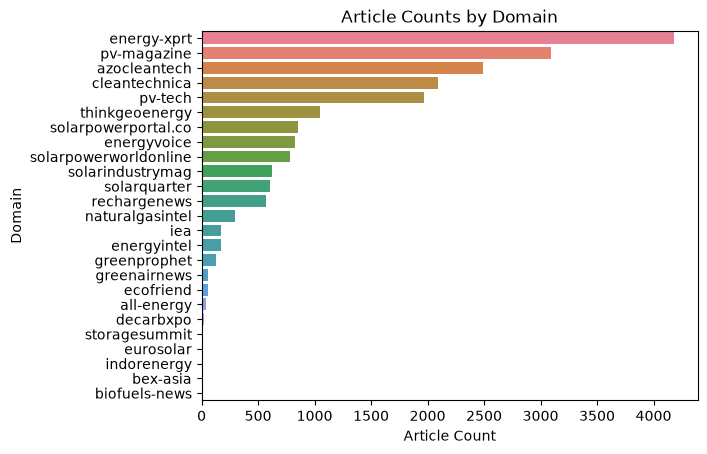

In [19]:
barplot = sns.barplot(
    x=domain_counts.values, 
    y=domain_counts.index,
    hue=domain_counts.index
)

barplot.set_title('Article Counts by Domain')
barplot.set_xlabel('Article Count')
barplot.set_ylabel('Domain')

plt.show()

Our exploration of article domains reveals a skewed distribution.  Publishers like cleantechnica have a significantly higher representation (1861 articles), while others like indoenergy have minimal contributions (2 articles).  If we proceed with sampling this data, this imbalance should be taken into account. [Stratified sampling](https://en.wikipedia.org/wiki/Stratified_sampling) is the recommended  approach to ensure a representative sample across different publishers.

### Article Dates

Each article within the dataset is accompanied by a publication date. Let's delve into the temporal range of these articles and investigate any noteworthy patterns in publication trends.

In [20]:
# plot the amount of articles over time
articles_df["date"] = pd.to_datetime(articles_df["date"])
time_df = articles_df.groupby("date").size().reset_index()
time_df.columns = ["date","count"]

time_df.describe()

,date,count
count,979,979.000000
mean,2023-05-26 05:11:49.703779,20.542390
min,2022-01-02 00:00:00,1.000000
25%,2022-09-19 12:00:00,8.000000
50%,2023-05-26 00:00:00,17.000000
75%,2024-01-30 12:00:00,23.000000
max,2024-10-24 00:00:00,1812.000000
std,NaN,76.837351


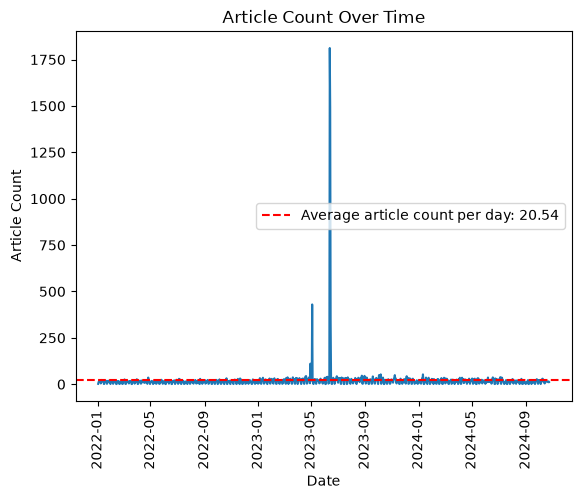

In [21]:
sns.lineplot(data=time_df, x="date", y="count")
plt.title("Article Count Over Time")
plt.xlabel("Date")
plt.xticks(rotation=90)
plt.ylabel("Article Count")
# add a line for the average
avg_count = time_df["count"].mean()
plt.axhline(avg_count, color='r', linestyle='--', label=f"Average article count per day: {avg_count:.2f}")
plt.legend()
plt.show()

While the daily article count appears consistent overall, a significant outlier disrupts the pattern on the 2023-12-05.  The cause of this outlier is undetermined, but it could potentially be the date the data was scraped and the default value assigned for missing dates. Since the publication date is not crucial for RAG pipeline, we can remove it.

In [22]:
articles_df = articles_df.drop(columns=["date"])

### Article Titles

As noted in our initial exploration, some articles share identical titles. Here, we'll focus on identifying and handling these duplicate titles to ensure a clean and consistent dataset for our RAG pipeline.

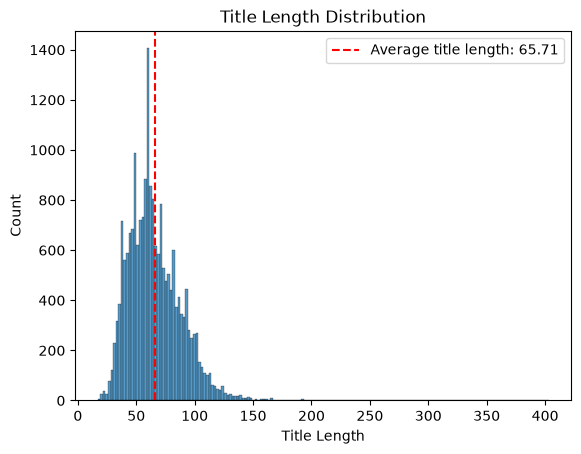

In [23]:
sns.histplot(articles_df["title"].str.len())
plt.title("Title Length Distribution")
plt.xlabel("Title Length")
plt.ylabel("Count")
avg_count = articles_df["title"].str.len().mean()
plt.axvline(avg_count, color='r', linestyle='--', label=f"Average title length: {avg_count:.2f}")
plt.legend()
plt.show()

In [24]:
articles_df["title"].duplicated().sum()

np.int64(95)

In [25]:
duplicate_titles = articles_df[articles_df["title"].duplicated(keep=False)].sort_values("title")
duplicate_titles.head(10)

,title,content,domain,url
105527,'Three quarters of power from wind ',['Three quarters of Dutch power will come from...,rechargenews,https://www.rechargenews.com/wind/three-quarte...
105526,'Three quarters of power from wind ',['Three quarters of Dutch power will come from...,rechargenews,https://www.rechargenews.com/wind/three-quarte...
22292,"ACWA Power: Quotes, Address, Contact","[""By clicking `` Allow All '' you agree to the...",azocleantech,https://www.azocleantech.com/Suppliers.aspx?Su...
13367,"ACWA Power: Quotes, Address, Contact",['We use cookies to enhance your experience. B...,azocleantech,https://www.azocleantech.com/suppliers.aspx?Su...
22256,"ADS-TEC Energy: Quotes, Address, Contact","[""By clicking `` Allow All '' you agree to the...",azocleantech,https://www.azocleantech.com/Suppliers.aspx?Su...
13371,"ADS-TEC Energy: Quotes, Address, Contact",['We use cookies to enhance your experience. B...,azocleantech,https://www.azocleantech.com/suppliers.aspx?Su...
22388,"ALUULA Composites Inc.: Quotes, Address, Contact","[""By clicking `` Allow All '' you agree to the...",azocleantech,https://www.azocleantech.com/Suppliers.aspx?Su...
13366,"ALUULA Composites Inc.: Quotes, Address, Contact",['We use cookies to enhance your experience. B...,azocleantech,https://www.azocleantech.com/suppliers.aspx?Su...
22396,"AMETEK STC: Quotes, Address, Contact","[""By clicking `` Allow All '' you agree to the...",azocleantech,https://www.azocleantech.com/Suppliers.aspx?Su...
13375,"AMETEK STC: Quotes, Address, Contact",['We use cookies to enhance your experience. B...,azocleantech,https://www.azocleantech.com/suppliers.aspx?Su...


In [26]:
duplicate_titles["content"].duplicated().sum()

np.int64(6)

Our exploration identified 24 titles that appear multiple times in the dataset. Examples include "About David J. Cross." Interestingly, while the titles are identical, the content itself appears to be unique.

Here are some additional observations for further investigation:
- A pattern was found where some articles begin with the phrase "By clicking." We'll delve into this further to determine the potential impact when analzing the article contents.
- We can observe instances of articles with seemingly similar content but differing URLs containing "sgvoice.energyvoice.com" and "energyvoice.com." Let's explore these cases to understand the potential distinction between them.

In [27]:
def wrap_text(text: str, char_per_line=100) -> str:
    # for better readability, wrap the text at the last space before the char_per_line
    if len(text) < char_per_line:
        return text
    else:
        return text[:char_per_line].rsplit(' ', 1)[0] + '\n' + wrap_text(text[len(text[:char_per_line].rsplit(' ', 1)[0])+1:], char_per_line)

In [28]:
print(duplicate_titles.iloc[0]["title"])
print(wrap_text(duplicate_titles.iloc[0]["content"]))

'Three quarters of power from wind '
['Three quarters of Dutch power will come from wind by 2031, the chief of the Netherlands Wind
Energy Association predicted, shortly after the government opened bidding for each of the Ijmujiden
Ver offshore wind sites, known respectively as Alpha 2GW and Beta 2GW.', 'Interested parties can
hand in bids between up to March 28 for the twin far offshore zones in the North Sea, in what is
the country’ s largest tender for wind at sea so far.', 'Recharge is part of DN Media Group. To
read more about DN Media Group, click here', 'Recharge is part of DN Media Group AS. From November
1st DN Media Group is responsible for controlling your data on Recharge.', 'We use your data to
ensure you have a secure and enjoyable user experience when visiting our site. You can read more
about how we handle your information in our privacy policy.', 'DN Media Group is the leading news
provider in the shipping, seafood, and energy industries, with a number of English- and


In [29]:
print(duplicate_titles.iloc[1]["title"])
print(wrap_text(duplicate_titles.iloc[1]["content"]))

'Three quarters of power from wind '
['Three quarters of Dutch power will come from wind by 2031, the chief of the Netherlands Wind
Energy Association predicted, shortly after the government opened bidding for each of the Ijmujiden
Ver offshore wind sites, known respectively as Alpha 2GW and Beta 2GW.', 'Interested parties can
hand in bids between up to March 28 for the twin far offshore zones in the North Sea, in what is
the country’ s largest tender for wind at sea so far.', 'Recharge is part of DN Media Group. To
read more about DN Media Group, click here', 'Recharge is part of DN Media Group AS. From November
1st DN Media Group is responsible for controlling your data on Recharge.', 'We use your data to
ensure you have a secure and enjoyable user experience when visiting our site. You can read more
about how we handle your information in our privacy policy.', 'DN Media Group is the leading news
provider in the shipping, seafood, and energy industries, with a number of English- and


Our analysis suggests potential redundancy within certain articles. In some cases, the second article might appear to be the first article with an additional sentence appended at the end.

Let's take a closer look at these "energyvoice" articles and how the contents start and see if we can eliminate these redundancies.

In [30]:
energyvoice_articles = articles_df[articles_df["domain"].str.contains("energyvoice")]
energyvoice_articles.content.map(lambda x: x[:50]).value_counts()

content
['', '', 'The Megawatt Hour is the latest podcast     6
['A group of trade associations from across the en    3
['Two years after the Amazon Pledge Fund invested     3
['Bruno Roche, Global Head of Energy Transition, A    2
['Macquarie Group is betting the North Sea – engin    2
                                                     ..
['Europe’ s largest renewable energy developer Sta    1
['Five technologies will form the backbone of the     1
['The UK’ s largest proposed pumped storage hydro     1
['Great British Energy will allow Scotland to “ le    1
['With Prime Minister Keir Starmer hosting EU lead    1
Name: count, Length: 790, dtype: int64

In [31]:
def remove_prefix_articles(df: pd.DataFrame, prefix_len: int = 100) -> pd.DataFrame:
    """
    Takes O(n^2) time complexity
    If the first {prefix_len} characters of the article are the same, then we consider them as a prefix. 
    If an article is a prefix of a longer article, then we remove it.
    If an article is a prefix of longer article, but they have different titles, then we keep them.
    """

    df["char_len"] = df["content"].map(len)
    df = df.sort_values(by='char_len', ascending=True).reset_index(drop=True)

    # Initialize a list to keep the articles that are not prefixes of others
    non_prefix_articles = []

    for i, row in df.iterrows():
        is_prefix = False
        content_i = row['content'][:prefix_len]
        title_i = row['title']

        for j in range(i + 1, len(df)):
            content_j = df.at[j, 'content'][:prefix_len]
            title_j = df.at[j, 'title']

            if content_i == content_j:
                # If the prefix matches but the titles are different, we keep it
                if title_i != title_j:
                    continue
                else:
                    is_prefix = True
                    break

        if not is_prefix:
            non_prefix_articles.append(row)

    print(f"Removed {len(df) - len(non_prefix_articles)} prefix articles")
    return pd.DataFrame(non_prefix_articles)

In [32]:
energyvoice_articles = remove_prefix_articles(energyvoice_articles)
energyvoice_articles.content.map(lambda x: x[:100]).value_counts()

Removed 11 prefix articles


content
['', '', 'The Megawatt Hour is the latest podcast boxset brought to you by Energy Voice Out Loud in     6
['Two years after the Amazon Pledge Fund invested in Hippo Harvest, the company is selling its first    3
['A group of trade associations from across the energy sector have written to the Chancellor urging     3
['The Department for Business, Energy and Industrial Strategy ( BEIS) says it was dreaming of a gree    2
['DNV report shows Jotun’ s Baltoflake solution offers beyond 30 years’ protection for offshore asse    2
                                                                                                       ..
["Norway has overtaken Russia as western Europe's top gas supplier, data from state firms shows, ind    1
['The US Inflation Reduction Act is set to have a profound impact on investment in climate tech and     1
['Politicians are vowing to roll back green policies and downplaying climate change ahead of key ele    1
['Six months after becoming the chief 

There still seem to be be some redundancy, but we did manage to remove 11 duplicates.

### Article Contents

Having explored various aspects of our dataset, we now turn our attention to the heart of the matter: the article content itself. This section will delve into the analysis and preprocessing techniques we'll employ to ensure the content is high-quality and effectively utilized by our RAG pipeline.

We start with a visual inspection of the article content.

In [33]:
np.random.seed(7)
random_sample_id = np.random.choice(articles_df.index)
print(wrap_text(articles_df.loc[random_sample_id, "content"]))

['Axis Energy, Juniper Green Energy, ReNew, and Acme have emerged as winners in NTPC’ s auction for
1.5 GW of wind-solar hybrid projects connected to India’ s interstate transmission system ( ISTS).
The average price was INR 3.30 ( $ 0.040) /kWh.', 'NTPC has concluded its ( Tranche-IV) tender for
ISTS-connected wind-solar hybrid capacity, with an average tariff of INR 3.30/kWh.', 'ABC Cleantech
( Axis Energy) won the biggest portion of 750 MW by quoting the lowest tariff of INR 3.27/kWh.
Juniper Green Energy secured 300 MW at INR 3.29/kWh. The rest of the capacity was allocated to
ReNew ( 300 MW) and ACME Cleantech ( 150 MW) at INR 3.32/kWh.', 'The winning developers will set up
the projects on a build-own-operate ( BOO) basis. The projects can be located anywhere in India and
must connect to the ISTS.', 'This content is protected by copyright and may not be reused. If you
want to cooperate with us and would like to reuse some of our content, please contact: editors @
pv-magazine.com.'

Our initial examination reveals that article content is currently stored as a list of strings. To gain deeper understanding and facilitate preprocessing, we'll transform these lists into a more cohesive textual format.

In [34]:
articles_df['article'] = articles_df['content'].apply(lambda x: ' '.join(ast.literal_eval(x)))
print(wrap_text(articles_df.loc[random_sample_id, "article"]))

Axis Energy, Juniper Green Energy, ReNew, and Acme have emerged as winners in NTPC’ s auction for
1.5 GW of wind-solar hybrid projects connected to India’ s interstate transmission system ( ISTS).
The average price was INR 3.30 ( $ 0.040) /kWh. NTPC has concluded its ( Tranche-IV) tender for
ISTS-connected wind-solar hybrid capacity, with an average tariff of INR 3.30/kWh. ABC Cleantech (
Axis Energy) won the biggest portion of 750 MW by quoting the lowest tariff of INR 3.27/kWh.
Juniper Green Energy secured 300 MW at INR 3.29/kWh. The rest of the capacity was allocated to
ReNew ( 300 MW) and ACME Cleantech ( 150 MW) at INR 3.32/kWh. The winning developers will set up
the projects on a build-own-operate ( BOO) basis. The projects can be located anywhere in India and
must connect to the ISTS. This content is protected by copyright and may not be reused. If you want
to cooperate with us and would like to reuse some of our content, please contact: editors @
pv-magazine.com. Please be mind

In [35]:
articles_df["article"].duplicated().sum()

np.int64(43)

In [36]:
duplicate_articles = articles_df[articles_df["article"].duplicated(keep=False)].sort_values("article")
duplicate_articles

,title,content,domain,url,article
89712,Solar Plant Monitoring ( Solar Energy) Articles,"[""2023-01-10 00:00For buyers of energy meters,...",energy-xprt,https://www.energy-xprt.com/solar-energy/solar...,"2023-01-10 00:00For buyers of energy meters, t..."
92379,Solar Plant Monitoring ( Energy Monitoring) Ar...,"[""2023-01-10 00:00For buyers of energy meters,...",energy-xprt,https://www.energy-xprt.com/energy-monitoring/...,"2023-01-10 00:00For buyers of energy meters, t..."
89587,Backup Power ( Power Distribution) News,"[""A new report shows how California's premier ...",energy-xprt,https://www.energy-xprt.com/power-distribution...,A new report shows how California's premier pu...
91830,Backup Power ( Energy Management) News,"[""A new report shows how California's premier ...",energy-xprt,https://www.energy-xprt.com/energy-management/...,A new report shows how California's premier pu...
36044,Green Prophet - Page 22 of 703 - Sustainabilit...,"['A poetic look at climate change, drought and...",greenprophet,https://www.greenprophet.com/page/22/?utm_camp...,"A poetic look at climate change, drought and a..."
...,...,...,...,...,...
13364,"Mosaic Materials, Inc.: Quotes, Address, Contact",['We use cookies to enhance your experience. B...,azocleantech,https://www.azocleantech.com/Suppliers.aspx?Su...,We use cookies to enhance your experience. By ...
100455,How can policy help Portugal decarbonize? – pv...,['With ambitious decarbonization targets and a...,pv-magazine,https://www.pv-magazine.com/2024/04/09/will-ne...,With ambitious decarbonization targets and a f...
100453,Will new Portuguese administration reduce EU f...,['With ambitious decarbonization targets and a...,pv-magazine,https://www.pv-magazine.com/2024/04/09/will-ne...,With ambitious decarbonization targets and a f...
89383,Renewable Energy Storage ( Renewable Energy) A...,"[""YTL, as an company of electricity meter, thi...",energy-xprt,https://www.energy-xprt.com/renewable-energy/r...,"YTL, as an company of electricity meter, this ..."


Our analysis uncovers additional insights regarding content duplication. We observe cases where seemingly identical articles are reposted on the same domain but with different titles (excluding the "sgvoice.energyvoice.com" vs. "energyvoice.com" scenario previously addressed). Here, we'll strategically keep these duplicates where contents are the same but titles are different.

**Importance of Titles**

We keep these duplicate articles because titles can hold information relevant for our RAG pipeline. Consider a scenario where a user query uses an abbreviation, while the corresponding article only contains the abbreviation in the title, in the content always the full term is used. To bridge this gap, we'll prepend titles to the article content during preprocessing. This ensures that the retrieval process considers not only the content itself, but also the potentially informative titles.

**Next Step**

As previously noted, some articles exhibit standardized introductions, possibly artifacts of the data scraping process. We'll develop appropriate techniques to handle these introductions during preprocessing, ensuring they don't hinder the effectiveness of our RAG pipeline.

In [37]:
articles_df.article.map(lambda x: x[:50]).value_counts()

article
By clicking `` Allow All '' you agree to the stori    1365
We use cookies to enhance your experience. By cont     865
Sign in to get the best natural gas news and data.     295
Create a free IEA account to download our reports      173
window.dojoRequire ( [ `` mojo/signup-forms/Loader      31
                                                      ... 
The US Department of the Treasury ( DOT) has final       1
Developer EDP is piloting a robotic construction s       1
The volume of large-scale battery energy storage p       1
The comparison site Selfmade Energy shows, in addi       1
The perovskite-silicon tandem device has a two ter       1
Name: count, Length: 15021, dtype: int64

In [38]:
artifacts = [
    "By clicking `` Allow All '' you agree to the sto",
    "Sign in to get the best natural gas news and dat",
    "window.dojoRequire ( [ `` mojo/signup-forms/Load"
]

for artifact in artifacts:
    print(wrap_text(articles_df[articles_df.article.str.startswith(artifact)].article.iloc[0][:500]))
    print()

By clicking `` Allow All '' you agree to the storing of cookies on your device to enhance site
navigation, analyse site usage and support us in providing free open access scientific content.
More info. Waga Energy is joining forces with Steuben County ( New York, USA) on a Renewable
Natural Gas ( RNG) project at the county’ s Bath landfill. The RNG produced will be injected in the
local grid and used as a biofuel to decarbonize mobility. The Steuben County landfill will be the
first in the US to

Sign in to get the best natural gas news and data. Follow the topics you want and receive the daily
emails. Your email address * Your password * Remember me Continue Reset password Featured Content
News & Data Services Client Support Daily GPI Infrastructure | NGI All News Access Electric
transmission planners with the Eastern Interconnection, a major power grid serving two-thirds of
the United States and Canada, recently gave a favorable review in their assessment of how well
regional plans m

In [39]:
def remove_scrapping_artifacts(df: pd.DataFrame, column: str) -> pd.DataFrame:
    text_artifacts = [
        "By clicking `` Allow All '' you agree to the storing of cookies on your device to enhance site navigation, analyse site usage and support us in providing free open access scientific content. More info.",
        "Sign in to get the best natural gas news and data. Follow the topics you want and receive the daily emails. Your email address * Your password * Remember me Continue Reset password Featured Content News & Data Services Client Support"
    ]

    regex_artifacts = [
        r"window.dojoRequire \( \[ .*\}\) \}\) "
    ]

    for pattern in text_artifacts:
        df[column] = df[column].str.replace(pattern, '', regex=False)

    for pattern in regex_artifacts:
        df[column] = df[column].str.replace(pattern, '', regex=True)

    return df

In [40]:
articles_df = remove_scrapping_artifacts(articles_df, "article")
articles_df.article.map(lambda x: x[:50]).value_counts()

article
We use cookies to enhance your experience. By cont    865
Create a free IEA account to download our reports     173
Welcome to Edinburgh Instruments’ monthly blog cel     26
Hydrogen Technology Expo & Carbon Capture Technolo     22
 Daily GPI E & P | NGI All News Access The U.S. na     21
                                                     ... 
The US Department of the Treasury ( DOT) has final      1
Developer EDP is piloting a robotic construction s      1
The volume of large-scale battery energy storage p      1
The comparison site Selfmade Energy shows, in addi      1
The perovskite-silicon tandem device has a two ter      1
Name: count, Length: 16569, dtype: int64

Our efforts have successfully eliminated a substantial portion of the scrapping artifacts within the articles. However, some traces  still persist, likely remnants of past website navigation structures. While removing these remaining artifacts could offer further refinement, it also presents a significant challenge. Therefore, we'll acknowledge this for now and move onto further preprocessing such as filtering out articles that are not written in English.

In [41]:
articles_df["lang"] = articles_df["article"].map(detect)
articles_df["lang"].value_counts()

lang
en    20107
de        2
ru        1
es        1
Name: count, dtype: int64

We will first inspect the language-specific assessment of our texts.

In [42]:
articles_df[articles_df["lang"] != "en"]

,title,content,domain,url,article,lang
82317,"Open Letter to Presidents Putin, Biden, Zelens...","['EUROSOLAR, the European Association for Rene...",eurosolar,https://www.eurosolar.de/sektionen/russland/,"EUROSOLAR, the European Association for Renewa...",ru
126129,SMS group liefert Prozesstechnologie für das e...,['© SMS group liefert Prozesstechnologie für d...,decarbxpo,https://www.decarbxpo.com/en/News_Media/Magazi...,© SMS group liefert Prozesstechnologie für das...,de
82320,Internationale Konferenz für Energiespeicher m...,['Die nun zu Ende gegangene „ Internationale E...,eurosolar,https://www.eurosolar.de/2022/09/26/internatio...,Die nun zu Ende gegangene „ Internationale Ern...,de
101246,Solar + Storage España 2024 – pv magazine Inte...,"['The event will feature a conference, worksho...",pv-magazine,https://www.pv-magazine.com/pv-magazine-events...,"The event will feature a conference, workshops...",es


In [43]:
print(wrap_text(articles_df[articles_df["lang"] != "en"].iloc[1]["article"][1000:]))

ne bedeutende CO2-Reduzierung über die gesamte Prozesskette erreichen und uns damit von unseren
Marktbegleitern differenzieren. Wir haben uns bei diesem Projekt für SMS group entschieden, weil
uns ihre Expertise überzeugt hat, die sie in zahlreichen Projekten weltweit unter Beweis gestellt
haben. “ „ Wir sind sehr stolz darauf, die Technologie für das erste komplett klimaneutrale
Stahlwerk der Welt zu liefern “, sagte Burkhard Dahmen, Vorstandsvorsitzender der SMS group. „ Dies
ist nicht nur ein wichtiger Schritt für H2 Green Steel, sondern auch eine ausgezeichnete
Gelegenheit, unsere Kompetenz und unsere Mission der grünen Stahlerzeugung zu unterstreichen. “ SMS
group wird eine Midrex®-Direktreduktionsanlage, ein Elektrostahlwerk, eine CSP®
Nexus-Gieß-Walzanlage sowie einen fortschrittlichen Kaltwalz- und Bandanlagen-Komplex für die
Produktion eines breiten Produktmixes einschließlich hochfester Stahlgüten ( AHSS) und Stahlgüten
für die Automobilindustrie liefern. Führende Automobilhe

In [44]:
articles_df = articles_df[articles_df["lang"] == "en"]

Our exploration revealed a small number of articles containing non-English content (some in German and 1 with a Russian section).  Since most LLMs and embedding models are primarily trained on English text, removing these articles ensures compatibility with our chosen models for this notebook. For simplicity, we'll only focus on supporting English queries and responses within this RAG pipeline.

#### Challenges of Multilingual RAG Pipelines

Introducing multilingual capabilities into a RAG pipeline presents an additional layer of complexity. Here's a breakdown of some key challenges:

- **Multilingual Model Support:** Both the LLM and embedding models need to be proficient in all target languages (e.g., English and German). The LLM must be able to comprehend and generate text in these languages, while the embedding models should effectively map similar concepts across languages into the same semantic space.
- **Prompt Engineering for Multilingual Responses:** When a user submits a question in German, for instance, we'd ideally retrieve relevant articles, potentially also in English which can distract the LLM, and utilize prompt engineering to ensure the LLM generates a response in German.

#### Characters, Tokens and Words

Let us further analyze the contents of the articles. However, before we do so let us define the meaning of characters, tokens and words:
- **Characters:** The smallest unit of text, including letters, numbers, punctuation, and whitespace.
- **Tokens:** Most NLP models operate on tokens, which are sequences of characters that represent a semantic unit. These units can be words, subwords, or characters. Tokenization is the process of converting text into tokens. To see the tokenization process in action for the OpenAI GPT-4 model, check out the [OpenAI GPT-4 Tokenizer](https://platform.openai.com/tokenizer).
- **Words:** Just as in everyday's language, words are the building blocks of text. They are composed of one or more characters and are separated by whitespace.

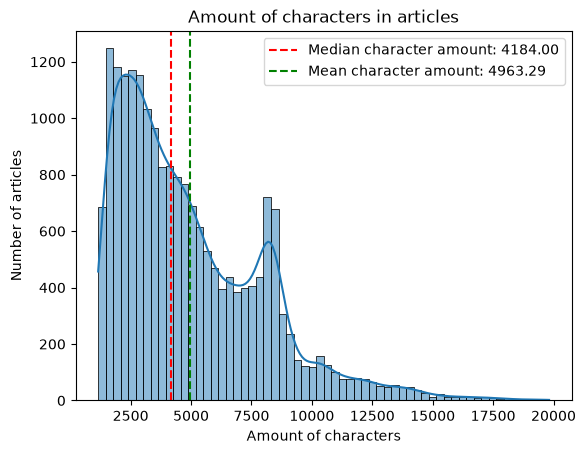

In [45]:
sns.histplot(articles_df["article"].map(len), kde=True)

plt.title("Amount of characters in articles")
plt.xlabel("Amount of characters")
plt.ylabel("Number of articles")
median_char_len = articles_df["article"].map(len).median()
mean_char_len = articles_df["article"].map(len).mean()
plt.axvline(median_char_len, color='r', linestyle='--', label=f"Median character amount: {median_char_len:.2f}")
plt.axvline(mean_char_len, color='g', linestyle='--', label=f"Mean character amount: {mean_char_len:.2f}")
plt.legend()
plt.show()

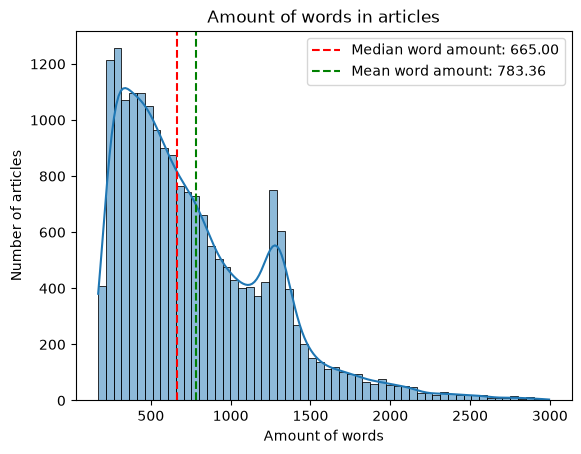

In [46]:
sns.histplot(articles_df["article"].map(lambda x: len(x.split())), kde=True)

plt.title("Amount of words in articles")
plt.xlabel("Amount of words")
plt.ylabel("Number of articles")
median_word_len = articles_df["article"].map(lambda x: len(x.split())).median()
mean_word_len = articles_df["article"].map(lambda x: len(x.split())).mean()
plt.axvline(median_word_len, color='r', linestyle='--', label=f"Median word amount: {median_word_len:.2f}")
plt.axvline(mean_word_len, color='g', linestyle='--', label=f"Mean word amount: {mean_word_len:.2f}")
plt.legend()
plt.show()

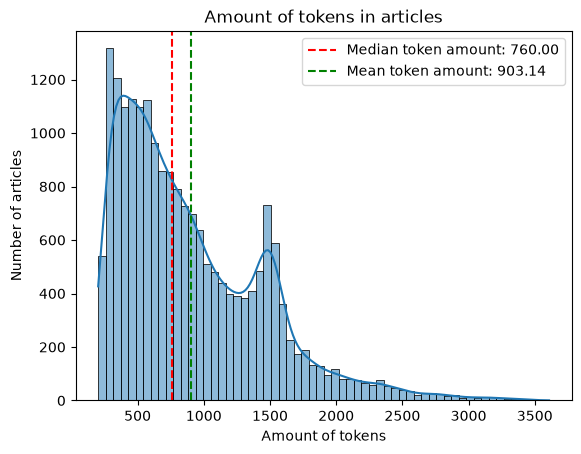

In [47]:
nlp = English()
tokenizer = nlp.tokenizer

token_lengths = articles_df["article"].map(lambda text: len(tokenizer(text)))
sns.histplot(token_lengths, kde=True)

plt.title("Amount of tokens in articles")
plt.xlabel("Amount of tokens")
plt.ylabel("Number of articles")
median_token_len = token_lengths.median()
mean_token_len = token_lengths.mean()
plt.axvline(median_token_len, color='r', linestyle='--', label=f"Median token amount: {median_token_len:.2f}")
plt.axvline(mean_token_len, color='g', linestyle='--', label=f"Mean token amount: {mean_token_len:.2f}")
plt.legend()
plt.show()

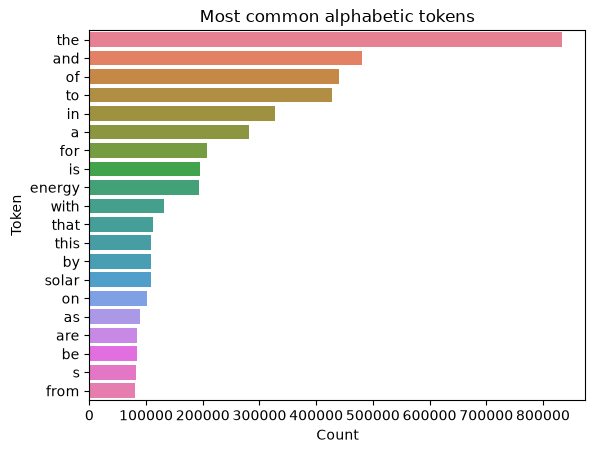

In [48]:
# Count incrementally rather than keeping every token from the corpus in RAM.
alpha_token_counts = Counter(
    token.text.lower()
    for document in nlp.pipe(articles_df["article"], batch_size=64)
    for token in document if token.is_alpha
)

sns.barplot(
    x=[count for token, count in alpha_token_counts.most_common(20)],
    y=[token for token, count in alpha_token_counts.most_common(20)],
    hue=[token for token, count in alpha_token_counts.most_common(20)]
)

plt.title("Most common alphabetic tokens")
plt.xlabel("Count")
plt.ylabel("Token")
plt.show()

The initial approach returns common words which do not reflect the subject-specific nature of our document collection. We will remove them to understand the content of the texts better. 

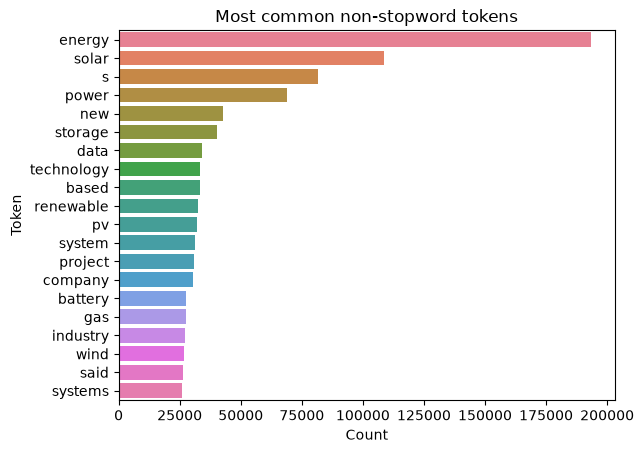

In [49]:
# remove stopwords such as 'the', 'a', 'and'
non_stop_token_counts = Counter({
    token: count for token, count in alpha_token_counts.items()
    if not nlp.vocab[token].is_stop
})

sns.barplot(
    x=[count for token, count in non_stop_token_counts.most_common(20)],
    y=[token for token, count in non_stop_token_counts.most_common(20)],
    hue=[token for token, count in non_stop_token_counts.most_common(20)]
)

plt.title("Most common non-stopword tokens")
plt.xlabel("Count")
plt.ylabel("Token")
plt.show()

As one would expect in a dataset of cleantech news articles most of the tokens that are not punctation or stopwords revolve around the subjects of energy, climate, and technology. This is a good sign that the dataset is relevant to the topic at hand. The "s" token comes up frequently, which is likely due to the possessive form of words. With an average of around 700 words per article, we can expect a good amount of information to be present in each article and an average reading time of around 3-4 minutes.

#### Flesch Reading Ease Score

The Flesch Reading Ease Score (FRES, a.k.a Flesch-Kincaid Reading Ease Score) is a heuristic used to evaluate how easy it is to understand a text based on the length of sentences and the number of syllables per word. Scores can range from -100 (very difficult to read) to 100 (very easy to read). Scores below 50 are indicative of difficult texts for College level. This metric can be useful for assessing the readability of our articles and ensuring they are accessible to a broad audience.

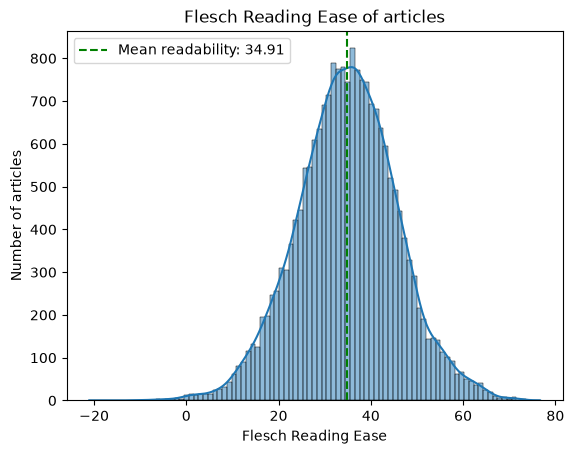

In [50]:
articles_df["readability"] = articles_df["article"].apply(flesch_reading_ease)

sns.histplot(articles_df["readability"], kde=True)

plt.title("Flesch Reading Ease of articles")
plt.xlabel("Flesch Reading Ease")
plt.ylabel("Number of articles")
mean_readability = articles_df["readability"].mean()
plt.axvline(mean_readability, color='g', linestyle='--', label=f"Mean readability: {mean_readability:.2f}")
plt.legend()
plt.show()

We analyze now the diversity of language complexity used by different publishing domains.

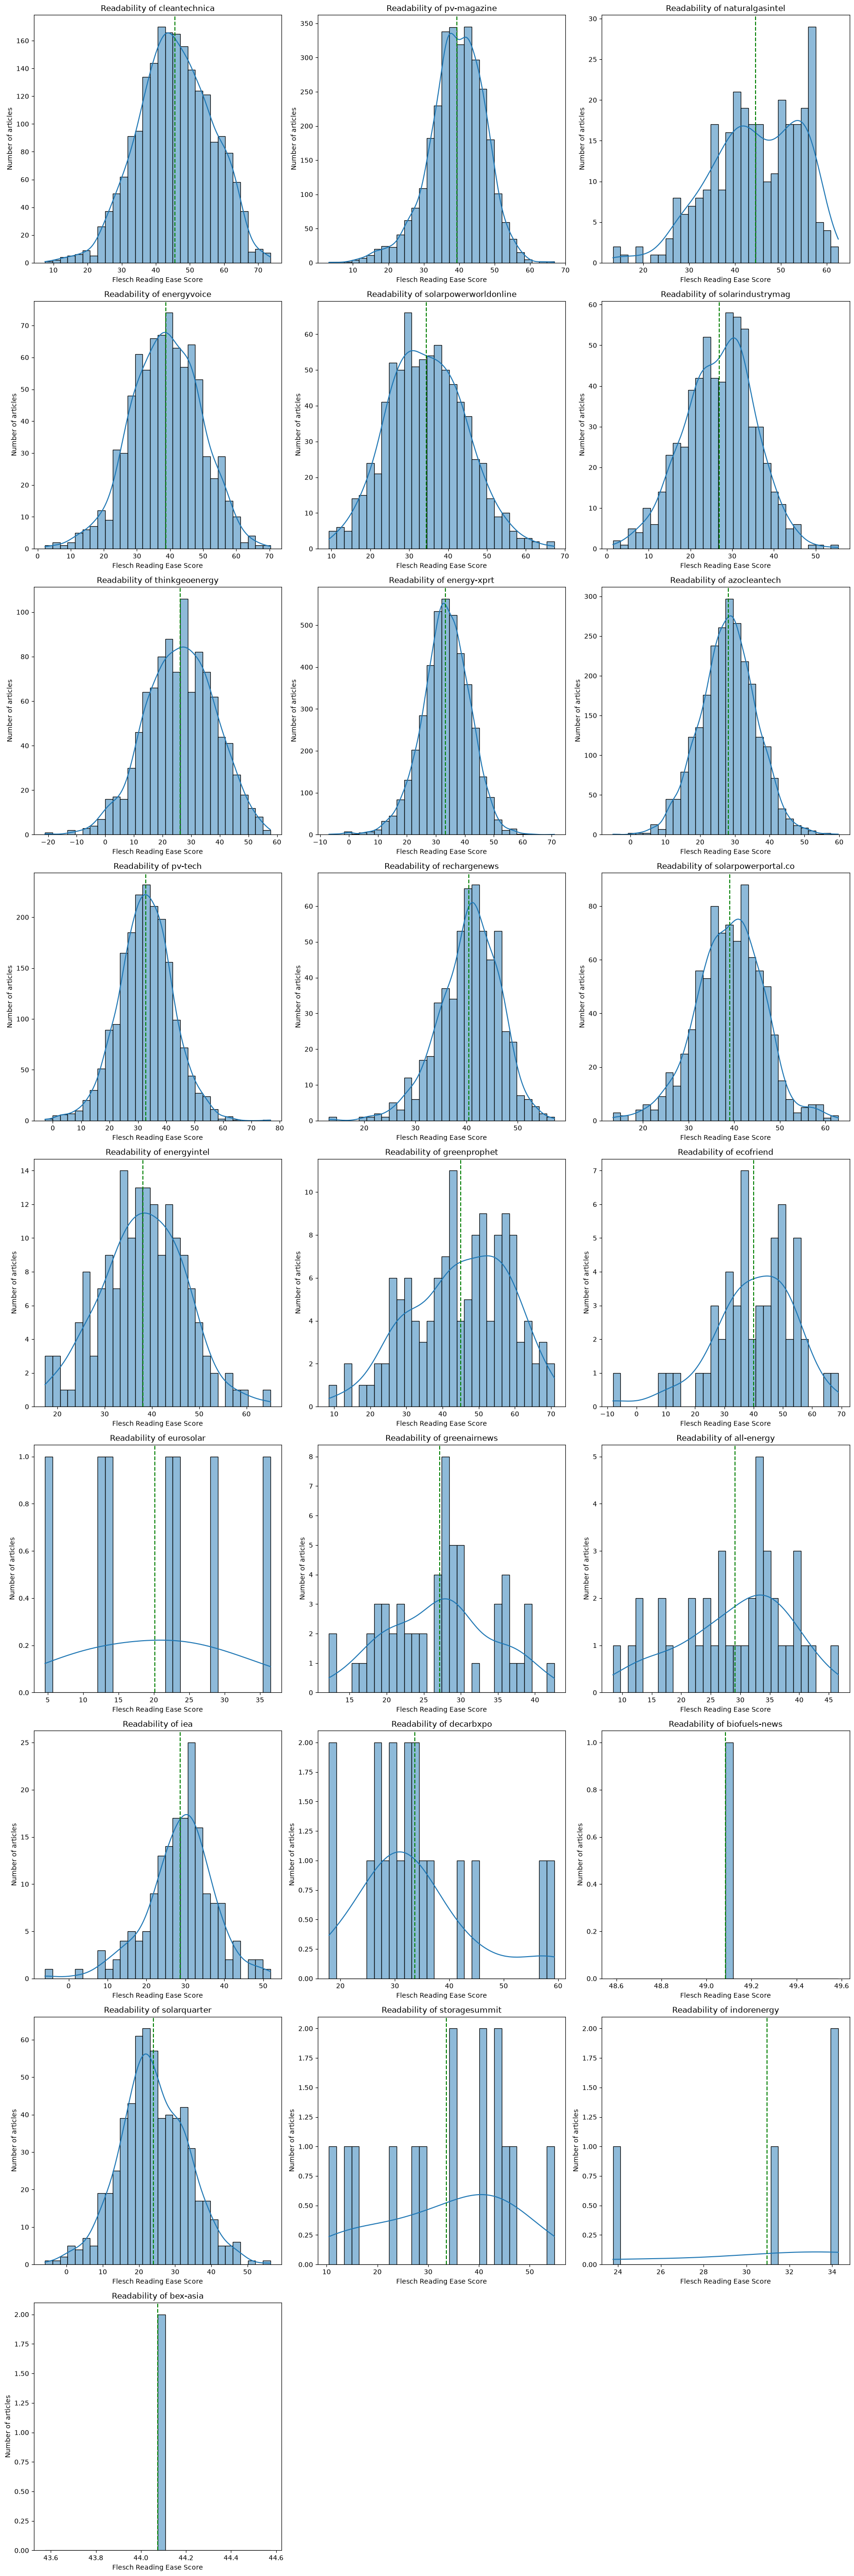

In [51]:
domains = articles_df["domain"].unique()

# Setup the subplots based on the number of domains
plots_per_row = 3
num_rows = (len(domains) + 2) // plots_per_row 
plot_height = 6 
fig, axes = plt.subplots(num_rows, plots_per_row, figsize=(plot_height * plots_per_row, plot_height * num_rows))
axes = axes.flatten()  # Flatten the axes array for easier iteration

# Plot for each domain
for i, domain in enumerate(domains):
    domain_articles = articles_df[articles_df["domain"] == domain]
    sns.histplot(domain_articles["readability"], kde=True, ax=axes[i], bins=30)
    axes[i].set_title(f'Readability of {domain}')
    axes[i].set_xlabel('Flesch Reading Ease Score')
    axes[i].set_ylabel("Number of articles")
    mean_readability = domain_articles["readability"].mean()
    axes[i].axvline(mean_readability, color='g', linestyle='--', label=f"Mean readability: {mean_readability:.2f}")

# remove the empty plots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

To gauge the readability of our articles, we calculated the Flesch Reading Ease Score. The average score of around 45 indicates a "fairly easy" reading level, which is positive news. This suggests the content is likely accessible to a broad audience and, consequently, understandable by our RAG pipeline as well.

Our analysis revealed a consistent average Flesch Reading Ease Score across most of the identified domains, with minor variations. This indicates a relatively consistent level of readability across different publishers within the dataset.

Finally we will save the cleaned dataset to a new file in the `data/silver` folder.

In [52]:
silver_folder = data_folder / "silver"
if not silver_folder.exists():
    silver_folder.mkdir()

articles_df.to_csv(silver_folder / "articles.csv", index=False)

### Evaluation Data

Next we will analyze the provided evaluation data and ensure that they match the content of the articles.

In [53]:
human_eval_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 1 to 23
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   question_id    23 non-null     int64
 1   question       23 non-null     str  
 2   relevant_text  23 non-null     str  
 3   answer         23 non-null     str  
 4   article_url    23 non-null     str  
dtypes: int64(1), str(4)
memory usage: 12.8 KB


In [54]:
human_eval_df.rename(columns={"relevant_chunk": "relevant_section", "relevant_text": "relevant_section", "article_url": "url", "answer": "ground_truth"}, inplace=True)
human_eval_df.drop(columns=["question_id"], errors="ignore", inplace=True)
human_eval_df.head()

/var/folders/_q/ppmmtcws6nn0nkxcbswtl0vc0000gq/T/ipykernel_12595/1257177425.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  human_eval_df.rename(columns={"relevant_chunk": "relevant_section", "relevant_text": "relevant_section", "article_url": "url", "answer": "ground_truth"}, inplace=True)
/var/folders/_q/ppmmtcws6nn0nkxcbswtl0vc0000gq/T/ipykernel_12595/1257177425.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  human_eval_df.drop(columns=["question_id"], errors="ignore", inplace=True)


,question,relevant_section,ground_truth,url
example_id,,,,
1,What is the innovation behind Leclanché's new ...,Leclanché said it has developed an environment...,Leclanché's innovation is using a water-based ...,https://www.sgvoice.net/strategy/technology/23...
2,What is the EU’s Green Deal Industrial Plan?,The Green Deal Industrial Plan is a bid by the...,The EU’s Green Deal Industrial Plan aims to en...,https://www.sgvoice.net/policy/25396/eu-seeks-...
3,What is the EU’s Green Deal Industrial Plan?,The European counterpart to the US Inflation R...,The EU’s Green Deal Industrial Plan aims to en...,https://www.pv-magazine.com/2023/02/02/europea...
4,What are the four focus areas of the EU's Gree...,The new plan is fundamentally focused on four ...,The four focus areas of the EU's Green Deal In...,https://www.sgvoice.net/policy/25396/eu-seeks-...
5,When did the cooperation between GM and Honda ...,What caught our eye was a new hookup between G...,July 2013,https://cleantechnica.com/2023/05/08/general-m...


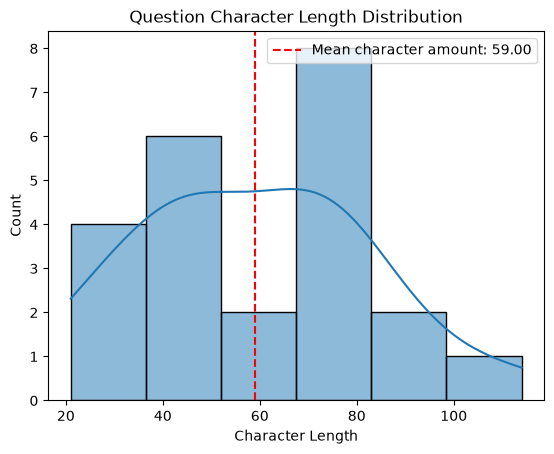

In [55]:
sns.histplot(human_eval_df["question"].map(len), kde=True)
plt.title("Question Character Length Distribution")
plt.xlabel("Character Length")
plt.ylabel("Count")
mean_char_len = human_eval_df["question"].map(len).mean()
plt.axvline(mean_char_len, color='r', linestyle='--', label=f"Mean character amount: {mean_char_len:.2f}")
plt.legend()
plt.show()

In [56]:
missing_articles = human_eval_df.copy()
missing_articles = missing_articles[~human_eval_df["url"].isin(articles_df["url"])]
missing_articles

,question,relevant_section,ground_truth,url
example_id,,,,
1,What is the innovation behind Leclanché's new ...,Leclanché said it has developed an environment...,Leclanché's innovation is using a water-based ...,https://www.sgvoice.net/strategy/technology/23...
2,What is the EU’s Green Deal Industrial Plan?,The Green Deal Industrial Plan is a bid by the...,The EU’s Green Deal Industrial Plan aims to en...,https://www.sgvoice.net/policy/25396/eu-seeks-...
4,What are the four focus areas of the EU's Gree...,The new plan is fundamentally focused on four ...,The four focus areas of the EU's Green Deal In...,https://www.sgvoice.net/policy/25396/eu-seeks-...
23,Which has the higher absorption coefficient fo...,We chose amorphous germanium instead of amorph...,amorphous germanium,https://www.pv-magazine.com/2021/01/15/germani...


Our exploration has identified instances where articles linked to specific questions appear to be missing from the dataset.  To determine the root cause, let's investigate whether these articles are genuinely absent or if inconsistencies in URL formatting are creating the illusion of missing data.  Normalizing the URLs across the dataset will help us differentiate between these two scenarios.

In [57]:
def normalize_url(url: str) -> str:
    url = url.replace("https://", "")
    url = url.replace("http://", "")
    url = url.replace("www.", "")
    url = url.rstrip("/")
    return url

articles_df["url"] = articles_df["url"].map(normalize_url)
human_eval_df["url"] = human_eval_df["url"].map(normalize_url)

missing_articles = human_eval_df.copy()
missing_articles = missing_articles[~human_eval_df["url"].isin(articles_df["url"])]
missing_articles

,question,relevant_section,ground_truth,url
example_id,,,,
1,What is the innovation behind Leclanché's new ...,Leclanché said it has developed an environment...,Leclanché's innovation is using a water-based ...,sgvoice.net/strategy/technology/23971/leclanch...
2,What is the EU’s Green Deal Industrial Plan?,The Green Deal Industrial Plan is a bid by the...,The EU’s Green Deal Industrial Plan aims to en...,sgvoice.net/policy/25396/eu-seeks-competitive-...
4,What are the four focus areas of the EU's Gree...,The new plan is fundamentally focused on four ...,The four focus areas of the EU's Green Deal In...,sgvoice.net/policy/25396/eu-seeks-competitive-...
23,Which has the higher absorption coefficient fo...,We chose amorphous germanium instead of amorph...,amorphous germanium,pv-magazine.com/2021/01/15/germanium-based-sol...


We also know from previous analysis that some duplicate articles from the "energyvoice" domain so we will also normalize these URLs.

In [58]:
missing_articles["url"] = missing_articles["url"].map(lambda x: x.replace("sgvoice.net", "sgvoice.energyvoice.com"))

In [59]:
missing_articles[~missing_articles["url"].isin(articles_df["url"])]

,question,relevant_section,ground_truth,url
example_id,,,,
23,Which has the higher absorption coefficient fo...,We chose amorphous germanium instead of amorph...,amorphous germanium,pv-magazine.com/2021/01/15/germanium-based-sol...


In [60]:
human_eval_df.loc[missing_articles.index, "url"] = missing_articles["url"]
human_eval_df[human_eval_df["url"].isin(articles_df["url"])]

,question,relevant_section,ground_truth,url
example_id,,,,
1,What is the innovation behind Leclanché's new ...,Leclanché said it has developed an environment...,Leclanché's innovation is using a water-based ...,sgvoice.energyvoice.com/strategy/technology/23...
2,What is the EU’s Green Deal Industrial Plan?,The Green Deal Industrial Plan is a bid by the...,The EU’s Green Deal Industrial Plan aims to en...,sgvoice.energyvoice.com/policy/25396/eu-seeks-...
3,What is the EU’s Green Deal Industrial Plan?,The European counterpart to the US Inflation R...,The EU’s Green Deal Industrial Plan aims to en...,pv-magazine.com/2023/02/02/european-commission...
4,What are the four focus areas of the EU's Gree...,The new plan is fundamentally focused on four ...,The four focus areas of the EU's Green Deal In...,sgvoice.energyvoice.com/policy/25396/eu-seeks-...
5,When did the cooperation between GM and Honda ...,What caught our eye was a new hookup between G...,July 2013,cleantechnica.com/2023/05/08/general-motors-se...
6,Did Colgate-Palmolive enter into PPA agreement...,"Scout Clean Energy, a Colorado-based renewable...",yes,solarindustrymag.com/scout-and-colgate-palmoli...
7,What is the status of ZeroAvia's hydrogen fuel...,"In December, the US startup ZeroAvia announced...",ZeroAvia's hydrogen fuel cell electric aircraf...,cleantechnica.com/2023/01/02/the-wait-for-hydr...
8,"What is the ""Danger Season""?",As spring turns to summer and the days warm up...,"The ""Danger Season"" is the period in the North...",cleantechnica.com/2023/05/15/what-does-a-norma...
9,Is Mississipi an anti-ESG state?,Mississippi is among two dozen or so states in...,yes,cleantechnica.com/2023/05/15/mississippi-takes...


In the end we are able to find all the articles that are linked to the evaluation data and have therefore successfully completed our exploratory data analysis and preprocessing.

## Subsampling

For faster processing and to reduce the cost of running the notebook we will subsample the dataset to 1000 articles. This will allow us to run the notebook in a reasonable amount of time and still provide meaningful results. Because the distribution of articles across publishers is skewed we will use stratified sampling to ensure that we have a representative sample. We also need to keep in mind that the evaluation data are linked to specific articles so we need to make sure that these are included in the subsample.

In [61]:
eval_articles_df = articles_df[articles_df["url"].isin(human_eval_df["url"])]
eval_articles_df.head()

,title,content,domain,url,article,lang,readability
93950,Agrivoltaics Goes Nuclear On California Prairie,['A decommissioned nuclear power plant from th...,cleantechnica,cleantechnica.com/2022/12/18/agrivoltaics-goes...,A decommissioned nuclear power plant from the ...,en,34.398901
93986,The Wait For Hydrogen Fuel Cell Electric Aircr...,['The US firm ZeroAvia is one step closer to b...,cleantechnica,cleantechnica.com/2023/01/02/the-wait-for-hydr...,The US firm ZeroAvia is one step closer to bri...,en,39.294468
43308,Leclanché’ s new disruptive battery boosts ene...,['Energy storage company Leclanché ( SW.LECN) ...,energyvoice,sgvoice.energyvoice.com/strategy/technology/23...,Energy storage company Leclanché ( SW.LECN) ha...,en,38.992500
21630,Quality Control System for Ocean Temperature I...,"[""By clicking `` Allow All '' you agree to the...",azocleantech,azocleantech.com/news.aspx?newsID=32873,"Over the last century, over 16 million ocean ...",en,28.169769
98795,European Commission introduces Green Deal Indu...,['The European Commission listed tax exemption...,pv-magazine,pv-magazine.com/2023/02/02/european-commission...,"The European Commission listed tax exemptions,...",en,37.423050


In [62]:
print(eval_articles_df["url"].unique().shape)
print(human_eval_df["url"].unique().shape)

(20,)
(21,)


In [63]:
def do_stratification(
        df: pd.DataFrame,
        column: str,
        sample_size: int,
        seed: int = 42
) -> pd.DataFrame:
    res_df = df.copy()
    indx = df.groupby(column, group_keys=False)[column].apply(lambda x: x.sample(n=int(sample_size/len(df) * len(x)), random_state=seed)).index.to_list()
    return res_df.loc[indx]

In [64]:
sample_df = do_stratification(articles_df, "domain", 1000, 69)
# if the articles are already in the subsample from the evaluation set, then we remove them, so we just want unique urls
sample_df = sample_df[~sample_df["url"].isin(eval_articles_df["url"])]
sample_df = pd.concat([sample_df, eval_articles_df])
sample_df.info()

<class 'pandas.DataFrame'>
Index: 1004 entries, 17313 to 63679
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        1004 non-null   str    
 1   content      1004 non-null   str    
 2   domain       1004 non-null   str    
 3   url          1004 non-null   str    
 4   article      1004 non-null   str    
 5   lang         1004 non-null   str    
 6   readability  1004 non-null   float64
dtypes: float64(1), str(6)
memory usage: 9.9 MB


To make sure that the distributional characteristics has not been changed by subsampling we visualize and compare both data sets in relative terms.

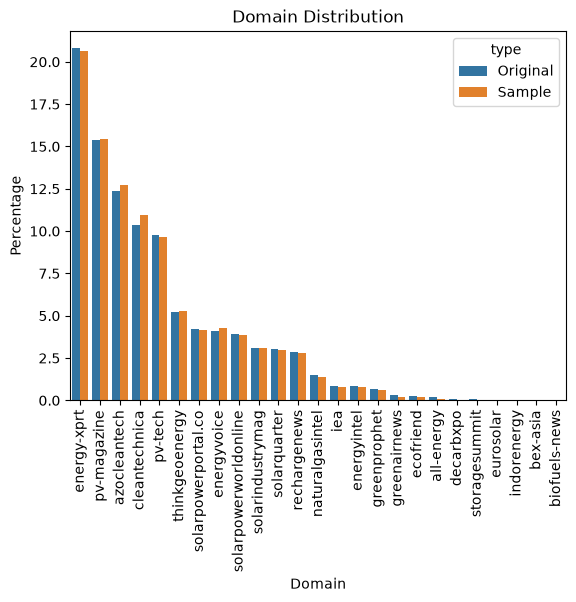

In [65]:
original_domain_counts = articles_df["domain"].value_counts().to_frame()
original_domain_counts = original_domain_counts / original_domain_counts.sum() * 100
domain_counts_df = original_domain_counts.copy()
domain_counts_df["type"] = "Original"


sample_domain_counts = sample_df["domain"].value_counts().to_frame()
sample_domain_counts = sample_domain_counts / sample_domain_counts.sum() * 100
sample_domain_counts["type"] = "Sample"

domain_counts_df = pd.concat([domain_counts_df, sample_domain_counts])
sns.barplot(
    x=domain_counts_df.index,
    y=domain_counts_df["count"],
    hue=domain_counts_df["type"]
)
plt.title("Domain Distribution")
plt.xlabel("Domain")
plt.ylabel("Percentage")
plt.xticks(rotation=90)
plt.show()

Now all is prepared to start developing our RAG! 

## Chunking

Chunking is a crucial step in the RAG pipeline. It involves breaking down the articles into smaller, more manageable pieces. 

![chunking](https://substackcdn.com/image/fetch/w_1456,c_limit,f_webp,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2F92c70184-ba0f-4877-9a55-e4add0e311ad_870x1116.gif)

There are mainly two reasons for this:
- **Generation:** The LLM has a limit on the number of tokens it can process at once. By chunking the articles, we can ensure that the LLM can generate responses without running into this limit. Another reason to use chunks for the generation step is to avoid "distractions" from irrelevant parts of the article. Just like if you were given a book and asked to answer a question about a the book it would be easier if you were just given the relevant chapter.
- **Retrieval:** Just like the LLM, the embedding model in the retrieval step has a limit on the number of tokens it can process at once. By chunking the articles, we can ensure that the embedding model can process the entire article. By chunking the articles, we can also improve the retrieval performance by having fine-grained chunks that can be matched more closely to the user query, rather then more general chunks.

Let's start by getting a better feeling for the most common size of chunks based on the number of characters

In [66]:
def get_lorem_text(num_chars: int) -> str:
    expected_avg_word_len = 3 # on the lower side to be safe
    text = lorem.words(num_chars // expected_avg_word_len)
    return text[:num_chars]

In [67]:
print(wrap_text(get_lorem_text(256)))

consectetur deleniti numquam magni molestiae animi quas accusamus qui tempora sapiente officiis ab
sequi voluptas eum porro corporis incidunt corrupti asperiores sed culpa repudiandae assumenda
voluptates a libero est ducimus mollitia earum harum expedita 


In [68]:
print(wrap_text(get_lorem_text(512)))

quos illum nisi cumque facilis voluptatem ex facere saepe enim eligendi distinctio consequatur
ipsam commodi voluptates adipisci doloribus praesentium recusandae temporibus beatae minima libero
aperiam eius architecto provident repellendus omnis odit perspiciatis nemo molestiae tenetur nobis
cupiditate aspernatur dolorem repellat explicabo est nam harum esse vitae mollitia culpa in iure
officiis deserunt minus ducimus placeat rerum qui a molestias hic veritatis cum sint impedit unde
repudiandae animi invent


In [69]:
print(wrap_text(get_lorem_text(1024)))

rerum nisi perferendis ullam molestias aut maiores hic expedita temporibus saepe minima quam cum
quaerat recusandae numquam ipsa consequuntur iste ratione ea unde voluptatum asperiores odit
doloribus aliquam nostrum mollitia natus praesentium vero perspiciatis quo magnam id laborum
necessitatibus distinctio maxime accusantium nobis modi corrupti a veritatis nesciunt earum animi
eius omnis fugit deleniti eum ab quasi tempore soluta quod autem suscipit quae nemo totam nihil vel
blanditiis enim officiis labore odio itaque quis commodi minus iusto facere doloremque ducimus
excepturi accusamus adipisci assumenda iure dicta ipsum corporis eveniet veniam repudiandae
reiciendis repellat voluptates aliquid illum neque harum cumque quisquam ex deserunt magni dolor
debitis esse facilis dolorem delectus voluptas molestiae similique eos impedit non quibusdam
voluptatibus atque sed ipsam eligendi quidem optio culpa voluptatem laboriosam placeat sunt tenetur
quas nulla reprehenderit obcaecati fugiat 

In [70]:
print(wrap_text(get_lorem_text(2048)))

quia quis hic atque facere ipsam rerum libero voluptatum aliquid quos officiis nam adipisci non
temporibus quidem delectus blanditiis ullam provident sunt quisquam eius quaerat quae obcaecati
exercitationem quo omnis nesciunt impedit repellat porro molestias ratione tempore possimus eveniet
minima velit expedita ea sed reiciendis ab repellendus nihil fuga dolorum sit fugit id unde qui
ipsa reprehenderit consectetur autem ad a eaque praesentium odit voluptate dolore amet laborum
nobis odio voluptatibus asperiores tenetur commodi mollitia dignissimos beatae consequuntur eum aut
aliquam explicabo repudiandae labore placeat cum cumque natus rem facilis sequi magni dolor officia
necessitatibus aspernatur in esse iusto earum perferendis ducimus neque ipsum modi iste nulla alias
illum quod aperiam totam quam voluptatem enim recusandae inventore quasi architecto laudantium
magnam fugiat minus assumenda cupiditate harum error sapiente eos incidunt itaque perspiciatis nemo
culpa dicta laboriosam

### Creating the Chunks

In this notebook we will be using two different chunking strategies:
- **Recursive Chunking:** This strategy involves recursively splitting the article into smaller chunks based on the article structure such as paragraphs and sentences until the chunk size is less than or equal to the maximum chunk size.
- **Semantic Chunking:** This strategy involves splitting the article into chunks based on semantic boundaries. This strategy finds boundaries between sentences that are semantically different and splits the article at these boundaries to create chunks. To do this we will need to use an embedding model to calculate the similarity between sentences. These embedding models will then also be used in the retrieval step to find the most relevant chunks.

To see how different texts get chunked with different strategies and chunk sizes check out the [Chunking Visualizer](https://chunkviz.up.railway.app/).

In [71]:
def get_recursive_splitter(chunk_size: int, chunk_overlap: int) -> TextSplitter:
    return RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=["\n\n", "\n", r"(?<=\. )", " ", ""],
        length_function=len,
        is_separator_regex=True,
    )

In [72]:
# the recursive splitter mainly relies on newlines, are there even any? No, so it will focus on sentences.
sample_df["article"].map(lambda x: x.count("\n")).sum()

np.int64(0)

Let us select the device: an NVIDIA GPU (CUDA) if available, otherwise Apple Silicon (MPS), otherwise the CPU. On a GPU the models run in half precision, which halves the memory and is much faster.

In [73]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

if device == "cuda" and torch.cuda.is_bf16_supported():
    dtype = torch.bfloat16
elif device in ("cuda", "mps"):
    dtype = torch.float16
else:
    dtype = torch.float32
print(f"Using device: {device} ({dtype})")

Using device: mps (torch.float16)


As embedding model we use [Qwen3-Embedding-4B](https://huggingface.co/Qwen/Qwen3-Embedding-4B). It is a 4B-parameter model built on the Qwen3 LLM, ranks near the top of the [MTEB leaderboard](https://huggingface.co/spaces/mteb/leaderboard) for its size and produces 2560-dimensional vectors. Some properties matter for our pipeline:

- **Instruction-aware queries:** queries are prefixed with a task instruction (`Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:`), documents are embedded as they are. The `query` prompt is stored with the model; `query_encode_kwargs` applies it to every query.
- **Long context:** it reads up to 32k tokens, so even our longest semantic chunks are embedded completely. Smaller encoders such as MPNet truncate after 384 tokens.
- **Memory:** in half precision the weights take about 8 GB of GPU memory. Later we add a reranker of the same size, so plan for roughly 16 GB in total.

We pin the model revision. Precomputed document embeddings are only valid with exactly the same model, revision, normalization and prompts. If you change any of these, delete the cached chunks, embeddings and indexes. To compare further models, add them to the `embedding_models` dictionary: every following step runs for each entry.

In [74]:
EMBEDDING_MODEL = "Qwen/Qwen3-Embedding-4B"
EMBEDDING_REVISION = "5cf2132abc99cad020ac570b19d031efec650f2b"

embedding_models = {
    "qwen3": HuggingFaceEmbeddings(
        model_name=EMBEDDING_MODEL,
        model_kwargs={
            "device": device,
            "revision": EMBEDDING_REVISION,
            "model_kwargs": {"dtype": str(dtype).removeprefix("torch.")},
        },
        encode_kwargs={"batch_size": 8, "normalize_embeddings": True},
        query_encode_kwargs={"batch_size": 8, "normalize_embeddings": True, "prompt_name": "query"},
    ),
}

Loading checkpoint shards: 100%|██████████| 2/2 [00:08<00:00,  4.34s/it]


We also define the chunking strategies to be used. The recursive splittering is characterized by the length of chunks and the overlap between adjacent chunks. For the semantic chunking, sentences embedded as dense vectors are merged as long as the cosine distance between two consecutive sentences does not exceed a percentile based threshold.

In [75]:
recursive_256_splitter = get_recursive_splitter(256, 64)
recursive_1024_splitter = get_recursive_splitter(1024, 128)
semantic_splitter = SemanticChunker(
    embedding_models["qwen3"], breakpoint_threshold_type="percentile"
)
splitters = {
    "recursive_256": recursive_256_splitter,
    "recursive_1024": recursive_1024_splitter,
    "semantic": semantic_splitter
}

In [76]:
def chunk_documents(df: pd.DataFrame, text_splitter: TextSplitter):
    chunks = []
    id = 0
    for _, row in tqdm(df.iterrows(), total=len(df)):
        article_content = row['article']
        title = row['title']
        # we add the title to the content as it might be relevant to the question
        full_text = title + ": " + article_content
        char_chunks = text_splitter.split_text(full_text)
        for chunk in char_chunks:
                id += 1
                # add metadata to the chunk for potential later use
                metadata = {
                    'title': row['title'],
                    'url': row['url'],
                    'domain': row['domain'],
                    'id': id,
                }
                chunks.append(Document(
                    page_content=chunk,
                    metadata=metadata,
                ))
    return chunks

In [77]:
chunks_folder = silver_folder / "chunks"
if not chunks_folder.exists():
    chunks_folder.mkdir()

The following function will load existing chunks, prepared for our tutorial to speed up the preparation process.  

In [78]:
def get_or_create_chunks(df: pd.DataFrame, text_splitter: TextSplitter, splitter_name: str) -> List[Document]:
    chunks_file = chunks_folder / f"{splitter_name}_chunks.json"
    if chunks_file.exists():
        with open(chunks_file, "r") as file:
            chunks = [Document(**chunk) for chunk in json.load(file)]
        print(f"Loaded {len(chunks)} chunks from {chunks_file}")
    else:
        chunks = chunk_documents(df, text_splitter)
        with open(chunks_file, "w") as file:
            json.dump([doc.model_dump() for doc in chunks], file, indent=4)
        print(f"Saved {len(chunks)} chunks to {chunks_file}")
    return chunks

In [79]:
chunks = {}
for splitter_name, splitter in splitters.items():
    chunks[splitter_name] = get_or_create_chunks(sample_df, splitter, splitter_name)

Loaded 28530 chunks from data/silver/chunks/recursive_256_chunks.json
Loaded 6044 chunks from data/silver/chunks/recursive_1024_chunks.json
Loaded 3302 chunks from data/silver/chunks/semantic_chunks.json


Now that we have created and saved the chunks we can analyze them. We can already see above that the semantic chunks are generally larger than the recursive chunks. 

### Analyzing the Chunks

Let's start by looking at the first chunk of the first article to get a feeling for what the chunks look like depending on the chunking strategy and then we will look at the distribution of the chunk sizes and the number of chunks per article.

In [80]:
for splitter_name, splitter_chunks in chunks.items():
    print(f"{splitter_name} chunks:")
    print(wrap_text(splitter_chunks[0].page_content, char_per_line=150))
    print()

recursive_256 chunks:
Charging Ahead: The UK’ s Electric Vehicle Revolution: Change is sweeping the highways of the United Kingdom. Being responsible for 88% of passenger
miles and 79% of freight traffic, England's highways are crucial.

recursive_1024 chunks:
Charging Ahead: The UK’ s Electric Vehicle Revolution: Change is sweeping the highways of the United Kingdom. Being responsible for 88% of passenger
miles and 79% of freight traffic, England's highways are crucial. Aside from that, despite making up just 2% of roads, National Highways ' strategic
road network ( SRN) handles one-third of passenger miles and two-thirds of freight miles in England. Connectivity is crucial for investment,
community empowerment, and efficient domestic and international supply chains in the SRN. As they glide past their diesel and gasoline-powered
competitors, sleek electric cars ( EVs) are bringing with them the promise of a more environmentally friendly future. An important strategic change
driving t

In [81]:
def plot_chunk_lengths(chunks: List[Document], title: str):
    sns.histplot([len(chunk.page_content) for chunk in chunks], kde=True)
    plt.title(title)
    plt.xlabel("Chunk length (characters)")
    plt.ylabel("Number of chunks")
    median_chunk_len = np.median([len(chunk.page_content) for chunk in chunks])
    mean_chunk_len = np.mean([len(chunk.page_content) for chunk in chunks])
    plt.axvline(median_chunk_len, color='r', linestyle='--', label=f"Median chunk length: {median_chunk_len:.2f}")
    plt.axvline(mean_chunk_len, color='g', linestyle='--', label=f"Mean chunk length: {mean_chunk_len:.2f}")
    plt.legend()
    plt.show()

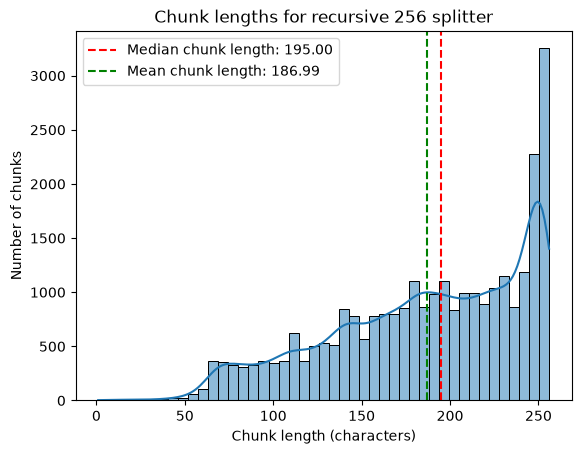

In [82]:
plot_chunk_lengths(chunks["recursive_256"], "Chunk lengths for recursive 256 splitter")

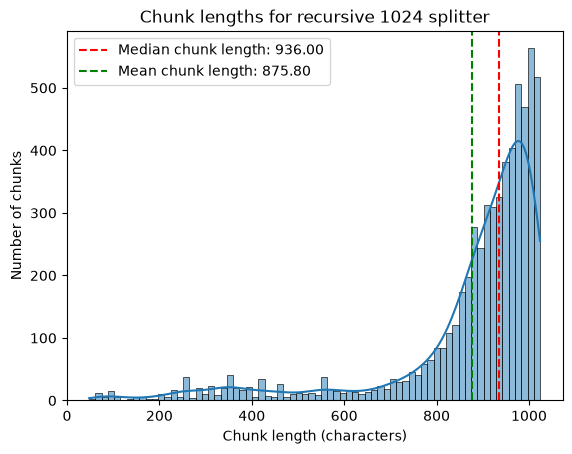

In [83]:
plot_chunk_lengths(chunks["recursive_1024"], "Chunk lengths for recursive 1024 splitter")

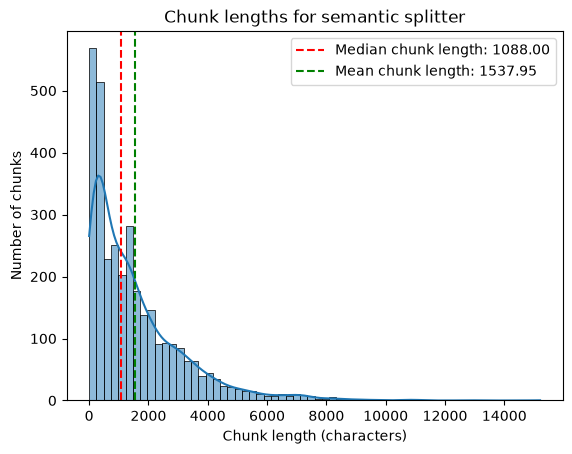

In [84]:
plot_chunk_lengths(chunks["semantic"], "Chunk lengths for semantic splitter")

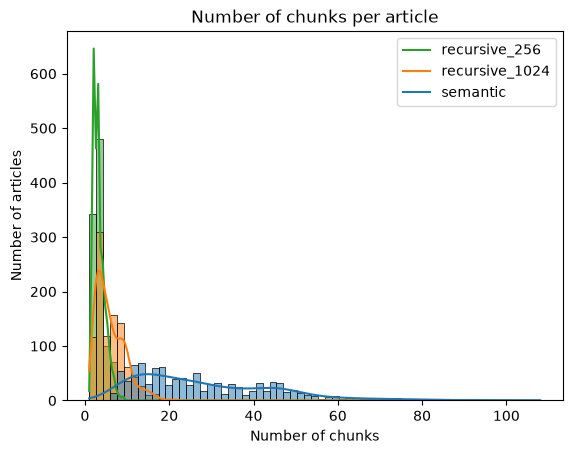

In [85]:
chunks_per_article = {splitter_name: Counter([chunk.metadata["title"] for chunk in chunks]) for splitter_name, chunks in chunks.items()}
counts = {splitter_name: [count for title, count in chunk_counts.items()] for splitter_name, chunk_counts in chunks_per_article.items()}

sns.histplot(counts, kde=True)
plt.title("Number of chunks per article")
plt.xlabel("Number of chunks")
plt.ylabel("Number of articles")
plt.legend(chunks_per_article.keys())
plt.show()

From our analysis of our created chunks we can see that the recursive chunks are all around the same size, close to the defined maximum. On the other hand, the semantic chunks vary in size. This is because the semantic chunking strategy is based on the semantic boundaries of the article. 

We can also see that despite the semantic chunks being larger, the distribution of the number of chunks per article is much wider for the recursive chunks. This is because the recursive chunks are all around the same size, while the semantic chunks have many smaller ones and a few larger ones.

## Generating Embeddings

Now that we have clean chunks, the next step involves generating embeddings for our article chunks. These embeddings will serve as a crucial component for efficient retrieval within the RAG pipeline. For our vector store we'll utilize ChromaDB, a powerful tool for indexing and searching high-dimensional data. To integrate our chosen embedding models with ChromaDB, we'll define a custom wrapper class. This wrapper class will act as an intermediary, ensuring seamless communication between the models and the ChromaDB indexing system.

In [86]:
class CustomChromadbEmbeddingFunction(EmbeddingFunction):
    def __init__(self, model=None, config=None) -> None:
        self._model = model
        self._config = config

    @property
    def model(self):
        # Chroma inspects serialized configurations during collection creation.
        # Load weights only if this reconstructed adapter is actually used.
        if self._model is None:
            self._model = HuggingFaceEmbeddings(**self._config)
        return self._model

    @staticmethod
    def name() -> str:
        return "cleantech-huggingface"

    def get_config(self):
        if self._config is not None:
            return self._config
        # Chroma stores this configuration with the collection. Leave out the
        # device so that the index also opens on a machine with other hardware.
        model_kwargs = {key: value for key, value in getattr(self.model, "model_kwargs", {}).items() if key != "device"}
        return {
            "model_name": self.model.model_name,
            "model_kwargs": model_kwargs,
            "encode_kwargs": getattr(self.model, "encode_kwargs", {}),
            "query_encode_kwargs": getattr(self.model, "query_encode_kwargs", {}),
        }

    @staticmethod
    def build_from_config(config):
        return CustomChromadbEmbeddingFunction(config=config)

    def embed_query(self, input: Documents) -> ChromaEmbeddings:
        # Chroma calls this for query_texts, so queries get the model's query instruction.
        return [self.model.embed_query(text) for text in input]

    def __call__(self, input: Documents) -> ChromaEmbeddings:
        return self.model.embed_documents(list(input))

We wrap every embedding model for ChromaDB and check that it produces vectors.

In [87]:
chroma_embedding_functions = {
    name: CustomChromadbEmbeddingFunction(model) for name, model in embedding_models.items()
}
for name, embedding_function in chroma_embedding_functions.items():
    sample = embedding_function(["Hello, world!"])[0]
    print(f"{name}: {len(sample)} dimensions, first values {np.round(sample[:5], 4)}")

qwen3: 2560 dimensions, first values [ 0.0001 -0.0483 -0.0061  0.0455  0.0003]


Generating embeddings can be a computationally intensive process. To optimize efficiency and avoid redundant computations, we'll leverage checkpointing: the vectors of each embedding model and chunking strategy are saved as a NumPy array whose rows line up with the saved chunks. We store them in half precision, which halves the file size; the model computes in half precision on a GPU anyway. A simple class pairs each chunk with its vector.

In [88]:
embeddings_folder = silver_folder / "embeddings"
if not embeddings_folder.exists():
    embeddings_folder.mkdir()

In [89]:
class DocumentEmbedding():
    def __init__(self, document: Document, text_embedding) -> None:
        self.document = document
        self.text_embedding = np.asarray(text_embedding, dtype=np.float32)

    def to_dict(self) -> Dict:
        return {
            "document": self.document.model_dump(),
            "text_embedding": self.text_embedding.tolist()
        }

    @classmethod
    def from_dict(cls, d: Dict) -> "DocumentEmbedding":
        return cls(
            document=Document(**d["document"]),
            text_embedding=d["text_embedding"]
        )


def get_or_create_embeddings(
        embedding_function: EmbeddingFunction,
        chunks: List[Document],
        embedding_name: str,
        batch_size: int = 512,  # large batches let the model sort texts by length and pad less
) -> List[DocumentEmbedding]:
    embeddings_file = embeddings_folder / f"{embedding_name}_embeddings.npy"
    if embeddings_file.exists():
        vectors = np.load(embeddings_file)
        if len(vectors) != len(chunks):
            raise ValueError(f"{embeddings_file} does not match the chunks; delete it to recompute.")
        print(f"Loaded {len(vectors)} embeddings from {embeddings_file}")
    else:
        vectors = []
        for start in tqdm(range(0, len(chunks), batch_size)):
            batch = chunks[start:start + batch_size]
            vectors.extend(embedding_function([chunk.page_content for chunk in batch]))
        vectors = np.asarray(vectors, dtype=np.float16)
        np.save(embeddings_file, vectors)
        print(f"Saved {len(vectors)} embeddings to {embeddings_file}")
    return [DocumentEmbedding(chunk, vector) for chunk, vector in zip(chunks, vectors, strict=True)]

In [90]:
embeddings = {}
for embedding_name, embedding_function in chroma_embedding_functions.items():
    for splitter_name, splitter_chunks in chunks.items():
        embeddings[f"{embedding_name}_{splitter_name}"] = get_or_create_embeddings(
            embedding_function, splitter_chunks, f"{embedding_name}_{splitter_name}"
        )

Loaded 28530 embeddings from data/silver/embeddings/qwen3_recursive_256_embeddings.npy
Loaded 6044 embeddings from data/silver/embeddings/qwen3_recursive_1024_embeddings.npy
Loaded 3302 embeddings from data/silver/embeddings/qwen3_semantic_embeddings.npy


The number of embeddings relates to the number of chunks produced by the individual chunking strategies, not the embedding dimensions. Thus smaller chunk size (e.g. 256) yields more chunks than larger chunk size (1024), and semantic embeddings even less chunks.

## Storing the Embeddings in ChromaDB

As mentioned above for our semantic search retrieval we will be storing the embeddings in ChromaDB. ChromaDB is a powerful tool for indexing and searching high-dimensional data. It is allows e.g. to use approximate nearest neighbor (ANN) search based on the Hierarchical Navigable Small World (HNSW) algorithm, which is known for its efficiency in searching high-dimensional spaces.

Just like with normal SQL databases we have a server, in this case an SQLite server, that we can connect to with a client. We will then use the client to connect to the server and create for each set of embeddings a new seperate database which can be thought of as the index or a vector space. ChromaDB calls these separate vector spaces "collections". These collections will then be used to search for the most relevant chunks to a user query.

![semantic search](https://images.contentstack.io/v3/assets/bltefdd0b53724fa2ce/bltf137a833984d3581/63728faba32209106e8b0b72/vector-search-diagram.png)

In [91]:
gold_folder = data_folder / "gold"
if not gold_folder.exists():
    gold_folder.mkdir()
chromadb_folder = gold_folder / "chromadb"
if not chromadb_folder.exists():
    chromadb_folder.mkdir()

chroma_client = chromadb.PersistentClient(path=chromadb_folder.as_posix())

Again we can make use of preprocessed data as before to speed up the preparatory steps.

In [92]:
def get_or_create_collection(
        name: str,
        embedding_function: EmbeddingFunction,
        embeddings: List[DocumentEmbedding],
        batch_size: int = 128
) -> Collection:

    collection = chroma_client.get_or_create_collection(
        name=name,
        # configure to use cosine distance not default L2
        configuration={"hnsw": {"space": "cosine"}},
        embedding_function=embedding_function
    )

    if collection.count() != len(embeddings):
        for i in tqdm(range(0, len(embeddings), batch_size)):
            batch = embeddings[i:i+batch_size]
            collection.upsert(
                documents=[embedding.document.page_content for embedding in batch],
                embeddings=[embedding.text_embedding for embedding in batch],
                ids=[str(embedding.document.metadata["id"]) for embedding in batch],
                metadatas=[embedding.document.metadata for embedding in batch]
            )

    return collection

In [93]:
collections = {}
for collection_name, current_embeddings in embeddings.items():
    collection = get_or_create_collection(
        collection_name,
        chroma_embedding_functions[collection_name.split("_")[0]],
        current_embeddings
    )
    collections[collection_name] = collection
    print(f"Collection {collection_name} has {collection.count()} documents")

Collection qwen3_recursive_256 has 28530 documents
Collection qwen3_recursive_1024 has 6044 documents
Collection qwen3_semantic has 3302 documents


The above printout shows the three embedding models applied to the three chunking strategies. 

Once we have stored all the embeddings in ChromaDB we can test the retrieval process by querying one of our collections and see what the most similar chunks are. Try some different queries and see what the most similar chunks are and whether they make sense.

In [94]:
selected_collection = collections["qwen3_recursive_1024"]
results = selected_collection.query(
    query_texts=["Climate Change"],
    n_results=3,
)
for doc in results["documents"][0]:
    print(wrap_text(doc))
    print()

Current climate models predict that between 2030 and 2052, global surface temperatures will likely
rise by 1.5 °C if human activities continue at their current pace. Here, the technologies
addressing global warming, Direct Air Carbon Capture ( DACCS) and Bioenergy Carbon Capture and
Storage ( BECCS), are discussed. Solar radiation management ( SRM) sparks perhaps the greatest
controversy of all proposed climate change prevention strategies. This article explores its
potential to be the future of fighting climate change. AZoCleantech has curated a collection of
articles that provide a deeper look into how the Clean Technology sector is responding to the
ongoing climate change crisis set out in the IPCC's 2018 Summary for Policymakers and 2021 Physical
Science Basis. The Sensi+™ is a laser-based analyzer used for monitoring natural gas quality. The
Cypher ES AFM from Oxford Instruments Asylum Research can be utilized for exceptional environmental
control.

There are clear signs that the 

## Analyzing the Embedding Space

To gain a better understandign of how the retrieval process works we will analyze the embedding space. We will start by projecting the embeddings into a 2D space using UMAP. UMAP is a dimensionality reduction technique that is particularly well-suited for visualizing high-dimensional data in a lower-dimensional space. The most notable advantages over other dimensionality reduction techniques are increased speed and better preservation of the data's global structure. We will then use the UMAP embeddings to create a scatter plot of the chunks.

In [95]:
def fit_umap(vectors: np.ndarray):
    return umap.UMAP(random_state=42).fit(vectors)

def project_embeddings(embeddings, umap_transform):
    if len(embeddings) == 0:
        return np.empty((0, 2))
    return umap_transform.transform(np.asarray(embeddings))

umap_cache = {}

def get_umap_projection(collection: Collection):
    """Fit UMAP once per collection and reuse it in all following plots."""
    if collection.name not in umap_cache:
        stored_chunks = collection.get(include=["embeddings", "metadatas"])
        vectors = np.array(stored_chunks["embeddings"])
        umap_transform = fit_umap(vectors)
        umap_cache[collection.name] = {
            "vectors": vectors,
            "umap": umap_transform,
            "projections": umap_transform.embedding_,  # 2D coordinates of the fitted vectors
            "metadatas": stored_chunks["metadatas"],
        }
    cached = umap_cache[collection.name]
    return cached["vectors"], cached["umap"], cached["projections"]

In [96]:
vectors, umap_transform, vectors_projections = get_umap_projection(selected_collection)
print(f"Original shape: {vectors.shape}")
print(f"Projected shape: {vectors_projections.shape}")

/Users/george.rowlands@fhnw.ch/workspace/Cleantech-RAG/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Original shape: (6044, 2560)
Projected shape: (6044, 2)


The dimensions above show how the chunk embeddings with 2560 dimensions are reduced to two dimensions for visualization purposes.

You can zoom in the plot by clicking and dragging a box around the area you want to zoom in on. You can also reset the plot by double clicking on the plot.

In [97]:
fig = px.scatter(x=vectors_projections[:, 0], y=vectors_projections[:, 1])
fig.show()

Next we will color the embeddings by the domain of the article to see if there are any patterns or clusters in the embedding space based on the domain.

In [98]:
fig = go.Figure()
chunk_domains = np.array([metadata["domain"] for metadata in umap_cache[selected_collection.name]["metadatas"]])
for domain in sample_df["domain"].unique():
    domain_projections = vectors_projections[chunk_domains == domain]
    fig.add_trace(go.Scatter(x=domain_projections[:, 0], y=domain_projections[:, 1], mode='markers', marker=dict(size=4), name=domain))

fig.show()

We can also visualize the retrieval process by plotting the query and the most similar chunks in the embedding space. This will give us a better understanding of how the retrieval process works and how the most similar chunks are found. 

Note that the UMAP projection uses a metric approach which differs from the approximate nearest neighbor approach used for retrieval. Also don't forget that the embeddings are in a high-dimensional space and we are only visualizing a 2D projection of them so the distances between the points might not be accurate. Try some different queries and see how the most similar chunks are found.

In [99]:
def plot_retrieval_results(
        query: str,
        selected_collection: Collection,
        n_results: int = 5
):
    vectors, umap_transform, vectors_projections = get_umap_projection(selected_collection)

    query_embedding = chroma_embedding_functions[selected_collection.name.split("_")[0]].embed_query([query])[0]
    query_embedding = np.array(query_embedding).reshape(1, -1)
    query_projection = project_embeddings(query_embedding, umap_transform)

    nearest_neighbors = selected_collection.query(
        query_texts=[query],
        n_results=n_results,
    )
    neighbor_vectors = selected_collection.get(include=["embeddings"], ids=nearest_neighbors["ids"][0])["embeddings"]
    neighbor_projections = project_embeddings(neighbor_vectors, umap_transform)
   

    fig = go.Figure()

    fig.add_trace(go.Scatter(x=vectors_projections[:, 0], y=vectors_projections[:, 1], mode='markers', marker=dict(size=5), name="other vectors"))
    fig.add_trace(go.Scatter(x=neighbor_projections[:, 0], y=neighbor_projections[:, 1], mode='markers', marker=dict(size=5, color='orange'), name="nearest neighbors"))
    fig.add_trace(go.Scatter(x=query_projection[:, 0], y=query_projection[:, 1], mode='markers', marker=dict(size=10, color='red', symbol='x'), name="query"))

    fig.show()

In [100]:
plot_retrieval_results(
    "Climate Change",
    selected_collection,
)

Lastly we will analyze the distribution of the cosine distances between the query and the different chunks. This will give us a better understanding of the cosine distance and show that the distances in the high-dimensional space are not the same as in the 2D projection. Do not confuse the cosine distance with the [cosine similarity](https://en.wikipedia.org/wiki/Cosine_similarity). The cosine similarity is the cosine of the angle between two vectors and the cosine distance is 1 minus the cosine similarity so that smaller numbers mean the vectors are more similar.

In [101]:
def cosine_distance(vector1, vector2):
    dot_product = np.dot(vector1, vector2.T)
    norm_product = np.linalg.norm(vector1) * np.linalg.norm(vector2)
    similarity = dot_product / norm_product
    return 1 - similarity

def plot_cosine_distances(
        query: str,
        selected_collection: Collection
):
    vectors, umap_transform, vectors_projections = get_umap_projection(selected_collection)

    query_embedding = chroma_embedding_functions[selected_collection.name.split("_")[0]].embed_query([query])[0]
    query_embedding = np.array(query_embedding).reshape(1, -1)
    query_projection = project_embeddings(query_embedding, umap_transform)

    similarities = np.array([cosine_distance(query_embedding, vector) for vector in vectors])

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=vectors_projections[:, 0],
        y=vectors_projections[:, 1],
        mode='markers',
        marker=dict(
            size=5,
            color=similarities.flatten(),
            colorscale='RdBu',
            colorbar=dict(title='Cosine Distance')
        ),
        text=['Cosine Distance: {:.4f}'.format(
            sim) for sim in similarities.flatten()],
        name='Other Vectors'
    ))

    fig.add_trace(go.Scatter(x=[query_projection[0][0]], y=[
                query_projection[0][1]], mode='markers', marker=dict(size=10, color='black', symbol='x'), text=['Query Vector'], name='Query Vector'))

    fig.show()

In [102]:
plot_cosine_distances(
    "Climate Change",
    selected_collection,
)

## Putting it all Together

Now that we have generated the embeddings and stored them in ChromaDB we can put it all together and create the RAG pipeline. The RAG pipeline consists of the following steps:
- **Indexing:** The first step is the preperation we have already done. We have chunked the articles and generated embeddings for the chunks and stored them in ChromaDB, our vector store/index.
- **Retrieval:** The next step in the RAG pipeline is to retrieve the most relevant chunks to the user query. This is done by querying the ChromaDB index with the user query and retrieving the most similar chunks.
- **Generation:** The next step is to generate a response to the user query. This is done by feeding the retrieved chunks and the user query to the LLM and generating a response.

### How does Langchain work?

In this notebook we will be using [Langchain](https://www.langchain.com/) to build up our pipeline. You do not need a library like Langchain or [LlamaIndex](https://www.llamaindex.ai/) to build a RAG pipeline, but it can make the process easier. 

The idea of Langchain and its LCEL (Langchain Expression Language) is very simple. Within the pipeline there are lots of steps that take an input and produce an output. These steps can be chained together to form a pipeline. The LCEL is a simple language that allows you to define these steps and how they are connected. For more technical details on how Langchain works check out the [Langchain Documentation](https://python.langchain.com/v0.1/docs/expression_language/).

In simple terms langchain provides an abstraction of a step that has an `invoke` method that takes an input, a dictionary of parameters and returns an output also a dictionary. This allows you to chain together different steps and define how they are connected and also split of chains of steps into separate pipelines.

Below you can see an overview of our RAG pipeline:

![rag_pipeline](https://miro.medium.com/v2/resize:fit:1400/0*XE_XZ3QrRhlB3b_q.png)

And now let's look at the implementation of the RAG pipeline.

In [103]:
def create_qa_chain(retriever: BaseRetriever):
    template = """You are an assistant for question-answering tasks. Use the following pieces of retrieved context to answer the question. \
    If you don't know the answer, just say that you don't know. Keep the answer concise.

    Question: {question}
    Context: {context}
    Answer:
    """
    rag_prompt = ChatPromptTemplate.from_template(template)

    def format_docs(docs):
        return "\n\n".join(doc.page_content for doc in docs)

    rag_chain = RunnableParallel(
        {
            "context": retriever,
            "question": RunnablePassthrough()
        }
    ).assign(answer=(
         RunnablePassthrough.assign(context=(lambda x: format_docs(x["context"])))
            | rag_prompt
            | llm
            | StrOutputParser()
    ))

    return rag_chain

For Langchain to work with our ChromaDB collections we need to transform the collections into a format that Langchain can work with so called stores and retrievers.

In [104]:
def collection_to_store(collection_name: str, lc_embedding_model: EmbeddingFunction):
    return Chroma(
        client=chroma_client,
        collection_name=collection_name,
        embedding_function=lc_embedding_model,
    )

def store_to_retriever(store: VectorStore, k: int = 3):
    retriever = store.as_retriever(
        search_type="similarity", search_kwargs={'k': k}
    )
    return retriever

In [105]:
selected_store = collection_to_store("qwen3_recursive_1024", embedding_models["qwen3"])
selected_retriever = store_to_retriever(selected_store)
selected_retriever.invoke("Climate Change")

[Document(id='539', metadata={'domain': 'azocleantech', 'title': 'Industrial Response to Climate Change', 'id': 539, 'url': 'azocleantech.com/industrial-response-to-climate-change.aspx'}, page_content="Current climate models predict that between 2030 and 2052, global surface temperatures will likely rise by 1.5 °C if human activities continue at their current pace. Here, the technologies addressing global warming, Direct Air Carbon Capture ( DACCS) and Bioenergy Carbon Capture and Storage ( BECCS), are discussed. Solar radiation management ( SRM) sparks perhaps the greatest controversy of all proposed climate change prevention strategies. This article explores its potential to be the future of fighting climate change. AZoCleantech has curated a collection of articles that provide a deeper look into how the Clean Technology sector is responding to the ongoing climate change crisis set out in the IPCC's 2018 Summary for Policymakers and 2021 Physical Science Basis. The Sensi+™ is a laser

Now that we have our retriever we can create our RAG pipeline. Try some different queries and see how the pipeline responds.

In [106]:
selected_chain = create_qa_chain(selected_retriever)
selected_chain.invoke("Where are the biggest increases in wildfire smoke exposure in recent years?")

{'context': [Document(id='6017', metadata={'title': 'What Does A “ Normal ” Year Of Wildfires Look Like In a Changing Climate?', 'url': 'cleantechnica.com/2023/05/15/what-does-a-normal-year-of-wildfires-look-like-in-a-changing-climate', 'domain': 'cleantechnica', 'id': 6017}, page_content='Surprisingly, some of the biggest increases in wildfire smoke exposure in recent years are in the Great Plains region, from North Dakota to Texas. In addition to their impact on air quality, wildfires can disrupt processes that maintain access to drinking water, including by reducing the ability of soil to absorb water when it rains and sending additional sediment into drinking water systems. The science is clear that climate change is increasing what’ s known as the “ vapor pressure deficit, ” or VPD, across western North America. When VPD is high, the atmosphere can pull more water out of plants, which dries them out and makes them more likely to burn. VPD also is also a good metric for drought, in

In [107]:
chains = {}
for collection_name, collection in collections.items():
    store = collection_to_store(collection_name, embedding_models[collection_name.split("_")[0]])
    retriever = store_to_retriever(store)
    chain = create_qa_chain(retriever)
    chains[collection_name] = chain

chains.keys()

dict_keys(['qwen3_recursive_256', 'qwen3_recursive_1024', 'qwen3_semantic'])

## Evaluation

Because we have many hyperparameters such as chunk size, prompts etc. to tune and different strategies to try we will use the [RAGAS (RAG Assesment) framework](https://docs.ragas.io/en/stable/) to evaluate our pipeline. RAGAS is a framework that allows you to evaluate your RAG pipeline with an LLM as a judge and other metrics that also utilize embedding models. We will go more into detail on the metrics later on. 

Before we can start the evaluation we need to define the evaluation questions and their ground truth answers. For this we will use the provided evaluation questions. To increase our question pool we will also generate some additional question and answer pairs based on a random chunk and utilizing the generator LLM (GPT-6.1 Sol) to generate the question and answer.

In [108]:
human_eval_df.head()

,question,relevant_section,ground_truth,url
example_id,,,,
1,What is the innovation behind Leclanché's new ...,Leclanché said it has developed an environment...,Leclanché's innovation is using a water-based ...,sgvoice.energyvoice.com/strategy/technology/23...
2,What is the EU’s Green Deal Industrial Plan?,The Green Deal Industrial Plan is a bid by the...,The EU’s Green Deal Industrial Plan aims to en...,sgvoice.energyvoice.com/policy/25396/eu-seeks-...
3,What is the EU’s Green Deal Industrial Plan?,The European counterpart to the US Inflation R...,The EU’s Green Deal Industrial Plan aims to en...,pv-magazine.com/2023/02/02/european-commission...
4,What are the four focus areas of the EU's Gree...,The new plan is fundamentally focused on four ...,The four focus areas of the EU's Green Deal In...,sgvoice.energyvoice.com/policy/25396/eu-seeks-...
5,When did the cooperation between GM and Honda ...,What caught our eye was a new hookup between G...,July 2013,cleantechnica.com/2023/05/08/general-motors-se...


The current version of the evaluation data includes a reference answer for each question, written together with the questions. The original 2024 version only contained the questions and the relevant sections of the articles. In that case, the next cell generates the reference answers with the generator LLM (GPT-6.1 Sol) from the relevant sections.

In [109]:
def generate_eval_answers(df: pd.DataFrame) -> pd.DataFrame:
    answer_geneation_prompt = """Answer the following question based on the article:
    Question: {question}
    Article: {article}
    """
    answer_generation_chain = ChatPromptTemplate.from_template(answer_geneation_prompt) | llm
    for i, row in tqdm(df.iterrows(), total=len(df)):
        df.at[i, "ground_truth"] = answer_generation_chain.invoke({"question": row["question"], "article": row["relevant_section"]}).content
    return df

In [110]:
if (silver_folder / "human_eval.csv").exists():
    human_eval_df = pd.read_csv(silver_folder / "human_eval.csv")
elif "ground_truth" not in human_eval_df or human_eval_df["ground_truth"].isna().any():
    human_eval_df = generate_eval_answers(human_eval_df)
    human_eval_df.to_csv(silver_folder / "human_eval.csv", index=False)

human_eval_df.head()

,question,relevant_section,ground_truth,url
example_id,,,,
1,What is the innovation behind Leclanché's new ...,Leclanché said it has developed an environment...,Leclanché's innovation is using a water-based ...,sgvoice.energyvoice.com/strategy/technology/23...
2,What is the EU’s Green Deal Industrial Plan?,The Green Deal Industrial Plan is a bid by the...,The EU’s Green Deal Industrial Plan aims to en...,sgvoice.energyvoice.com/policy/25396/eu-seeks-...
3,What is the EU’s Green Deal Industrial Plan?,The European counterpart to the US Inflation R...,The EU’s Green Deal Industrial Plan aims to en...,pv-magazine.com/2023/02/02/european-commission...
4,What are the four focus areas of the EU's Gree...,The new plan is fundamentally focused on four ...,The four focus areas of the EU's Green Deal In...,sgvoice.energyvoice.com/policy/25396/eu-seeks-...
5,When did the cooperation between GM and Honda ...,What caught our eye was a new hookup between G...,July 2013,cleantechnica.com/2023/05/08/general-motors-se...


We will now generate some synthetic questions and answers based on random chunks. So we will give the LLM a random chunk and ask it to generate a question and answer based on the chunk.

In [111]:
def generate_synthetic_qa_pairs(documents: List[Document], n: int = 10) -> List[str]:
    synthetic_questions = []
    rng = np.random.default_rng(42)
    documents = rng.choice(documents, n, replace=False)

    question_generation_prompt = """Generate a short and general question based on the following news article:
    Article: {article}
    """
    question_generation_chain = ChatPromptTemplate.from_template(question_generation_prompt) | llm

    answer_geneation_prompt = """Answer the following question based on the article:
    Question: {question}
    Article: {article}
    """
    answer_generation_chain = ChatPromptTemplate.from_template(answer_geneation_prompt) | llm


    for document in tqdm(documents):
        element = {}
        content = document.page_content
        element["relevant_section"] = content
        element["url"] = document.metadata["url"]
        question = question_generation_chain.invoke({"article": content}).content
        element["question"] = question
        answer = answer_generation_chain.invoke({"question": question, "article": content}).content
        element["ground_truth"] = answer
        synthetic_questions.append(element)

    return pd.DataFrame(synthetic_questions)

In [112]:
if not (silver_folder / "synthetic_eval.csv").exists():
    synthetic_eval_df = generate_synthetic_qa_pairs(chunks["recursive_1024"], 25)
    synthetic_eval_df.to_csv(silver_folder / "synthetic_eval.csv", index=False)
else:
    synthetic_eval_df = pd.read_csv(silver_folder / "synthetic_eval.csv")
synthetic_eval_df.head()

,relevant_section,url,question,ground_truth
0,CATL unveils first mass-producible battery sto...,pv-magazine.com/2024/04/12/catl-unveils-first-...,What makes CATL’s new energy storage system in...,CATL’s TENER is innovative because it is the w...
1,It will take place on Wednesday 8 July ( 10 am...,energy-xprt.com/energy-monitoring/energy-smart...,How can smart technology improve energy effici...,"Smart technology, such as smart meters and IoT..."
2,Wind Power To Cut Cargo Ship Emissions By 20%:...,cleantechnica.com/2022/12/06/wind-power-to-cut...,How can wind power reduce emissions from cargo...,Wind power can reduce cargo ship emissions by ...
3,Russia’ s invasion of Ukraine requires rapid r...,pv-tech.org/russias-invasion-of-ukraine-requir...,How could the war in Ukraine accelerate renewa...,The war could push countries to adopt renewabl...
4,Zach is recognized globally as an electric veh...,cleantechnica.com/2023/04/14/leader-leader-of-...,How does the Inflation Reduction Act affect af...,"According to the article, Chinese EV maker BYD..."


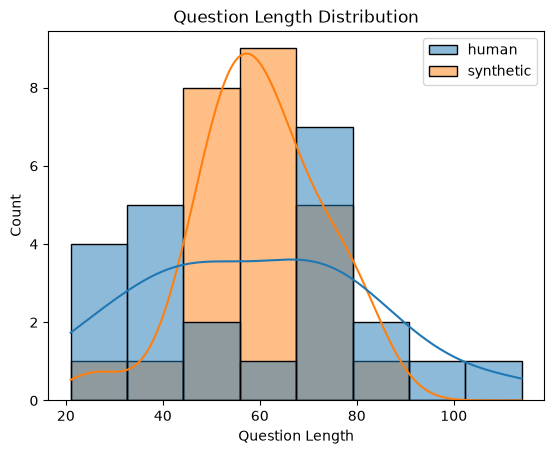

In [113]:
question_length = {
    "human": human_eval_df["question"].map(len),
    "synthetic": synthetic_eval_df["question"].map(len)
}

sns.histplot(question_length, kde=True)
plt.title("Question Length Distribution")
plt.xlabel("Question Length")
plt.ylabel("Count")
plt.show()

In [114]:
eval_df = pd.concat([
    human_eval_df.assign(is_synthetic=False),
    synthetic_eval_df.assign(is_synthetic=True),
], ignore_index=True)
eval_df["is_synthetic"].value_counts()

is_synthetic
True     25
False    23
Name: count, dtype: int64

Now we have doubled the number of questions and answers. However, we can see that our synthetic questions are slightly longer than the provided questions which could mean that they are slightly easier to answer. This potential bias should be taken into account when evaluating the pipeline.

### RAGAS Metrics

RAGAS provides a variety of metrics to evaluate the performance of a RAG pipeline. Here are some of the key metrics we will be using and how they are calculated:

- [Answer Relevancy](https://docs.ragas.io/en/stable/concepts/metrics/answer_relevance.html): This metric measures the relevance of the generated answer to the user query. The Answer Relevancy is defined as the mean cosine similartiy of the original question to a number of artifical questions, which where generated (reverse engineered) based on the answer.
- [Answer Correctness](https://docs.ragas.io/en/stable/concepts/metrics/answer_correctness.html): This metric measures the correctness of the generated answer. Answer correctness encompasses two critical aspects: semantic similarity between the generated answer and the ground truth, as well as factual similarity. These aspects are combined using a weighted scheme to formulate the answer correctness score.
- [Faithfulness](https://docs.ragas.io/en/stable/concepts/metrics/faithfulness.html): This metric measures how well the generated answer is faithful to the retrieved chunks. The generated answer is regarded as faithful if all the claims that are made in the answer can be inferred from the given context. To calculate this a set of claims from the generated answer is first identified. Then each one of these claims are cross checked with given context to determine if it can be inferred from given context or not.
- **Context Precision (with reference):** measures whether relevant retrieved chunks rank ahead of irrelevant chunks, using the reference answer. This replaces the removed `context_relevancy` metric; the scores are not directly comparable to the original workshop. New results are stored separately.

![ragas-metrics](https://substackcdn.com/image/fetch/w_1456,c_limit,f_webp,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2Fd3cfa382-3a0b-4424-b8c1-e0d4d4a1efec_1600x683.png)

For this to work we create a test dataset for each of our RAG pipelines that contains the evaluation questions and their ground truth answers. We then run all the questions through our RAG pipeline and store the generated answers and the retrieved chunks. We can then use this test dataset to calculate the RAGAS metrics.

In [115]:
datasets_folder = gold_folder / "datasets"
if not datasets_folder.exists():
    datasets_folder.mkdir()

def get_or_create_eval_dataset(name: str, df: pd.DataFrame, chain: Runnable) -> Dataset:
    dataset_file = datasets_folder/ f"{name}_dataset.json"
    if dataset_file.exists():
        with open(dataset_file, "r") as file:
            dataset = Dataset.from_dict(json.load(file))
        print(f"Loaded {name} dataset from {dataset_file}")
    else:
        datapoints = {
            "question": df["question"].tolist(),
            "answer": [],
            "contexts": [],
            "ground_truth": df["ground_truth"].tolist(),
            "context_urls": []
        }
        for question in tqdm(datapoints["question"]):
            result = chain.invoke(question)
            datapoints["answer"].append(result["answer"])
            datapoints["contexts"].append([str(doc.page_content) for doc in result["context"]])
            datapoints["context_urls"].append([doc.metadata["url"] for doc in result["context"]])
        dataset = Dataset.from_dict(datapoints)
        with open(dataset_file, "w") as file:
            json.dump(dataset.to_dict(), file)
        print(f"Saved {name} dataset to {dataset_file}")
    return dataset

In [116]:
results_folder = gold_folder / "results"
if not results_folder.exists():
    results_folder.mkdir()


class SymmetricEmbeddings(Embeddings):
    """RAGAS compares texts with each other (question vs. question, answer vs. reference).
    Embed both sides like documents, without the retrieval instruction used for queries."""
    def __init__(self, base: Embeddings) -> None:
        self.base = base

    def embed_documents(self, texts: List[str]) -> List[List[float]]:
        return self.base.embed_documents(texts)

    def embed_query(self, text: str) -> List[float]:
        return self.base.embed_documents([text])[0]


def get_or_run_llm_eval(name: str, dataset: Dataset, llm_judge_model: LLM) -> pd.DataFrame:
    eval_results_file = results_folder / f"{name}_llm_eval_results.csv"
    if eval_results_file.exists():
        eval_results = pd.read_csv(eval_results_file)
        print(f"Loaded {name} evaluation results from {eval_results_file}")
    else:
        eval_results = evaluate(dataset,
                                metrics=[Faithfulness(), ResponseRelevancy(), LLMContextPrecisionWithReference(), AnswerCorrectness()],
                                # GPT-6 models only accept the default temperature and one completion per request.
                                llm=LangchainLLMWrapper(llm_judge_model, bypass_temperature=True, bypass_n=True),
                                embeddings=LangchainEmbeddingsWrapper(SymmetricEmbeddings(embedding_models["qwen3"])),
                                raise_exceptions=True,
                                run_config=RunConfig(
                                    timeout=120, max_retries=10, max_wait=60, max_workers=8),
                                ).to_pandas()
        eval_results.to_csv(eval_results_file, index=False)
        print(f"Saved {name} evaluation results to {eval_results_file}")
    return eval_results

In [117]:
def plot_llm_eval(name: str, eval_results: pd.DataFrame):
    # select only the float64 columns (assuming these are the RAGAS metrics)
    ragas_metrics_data = (eval_results
                        .select_dtypes(include=[np.float64]))


    # boxplot of distributions
    sns.boxplot(data=ragas_metrics_data, palette="Set2")
    plt.title(f'{name}: Distribution of RAGAS Evaluation Metrics')
    plt.ylabel('Scores')
    plt.xlabel('Metrics')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # barplot of means
    means = ragas_metrics_data.mean()
    plt.figure(figsize=(14, 8))
    sns.barplot(x=means.index, y=means, palette="Set2")
    plt.title(f'{name}: Mean of RAGAS Evaluation Metrics')
    plt.ylabel('Mean Scores')
    plt.xlabel('Metrics')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [118]:
def plot_multiple_evals(eval_results: Dict[str, pd.DataFrame]):
    # combine the results
    full_results = []
    for name, results in eval_results.items():
        results['name'] = name
        full_results.append(results)

    full_results = pd.concat(full_results, ignore_index=True)
    full_results = full_results.sort_values(by='name')


    # select only the float64 columns (assuming these are the RAGAS metrics)
    ragas_metrics_data = full_results.select_dtypes(include=[np.float64])
    ragas_metrics_data['name'] = full_results['name']
    
    # boxplot of distributions
    plt.figure(figsize=(14, 8))
    sns.boxplot(x='variable', y='value', hue='name', data=pd.melt(ragas_metrics_data, id_vars='name'), palette="Set2")
    plt.title('Distribution of RAGAS Evaluation Metrics by Model')
    plt.ylabel('Scores')
    plt.xlabel('Metrics')
    plt.xticks(rotation=45)
    plt.legend(title='Model')
    plt.tight_layout()
    plt.show()
    
    # barplot of means
    means = ragas_metrics_data.groupby('name').mean().reset_index()
    means_melted = pd.melt(means, id_vars='name')
    
    plt.figure(figsize=(14, 8))
    sns.barplot(x='variable', y='value', hue='name', data=means_melted, palette="Set2")
    plt.title('Mean of RAGAS Evaluation Metrics by Model')
    plt.ylabel('Mean Scores')
    plt.xlabel('Metrics')
    plt.xticks(rotation=45)
    plt.legend(title='Model')
    plt.tight_layout()
    plt.show()

In [119]:
selected_dataset = get_or_create_eval_dataset("selected", eval_df, selected_chain)

Loaded selected dataset from data/gold/datasets/selected_dataset.json


As a judge we use **GPT-6 Luna**. It is OpenAI's cheaper model of the GPT-6 generation: less capable than GPT-6.1 Sol, but strong enough to check claims against a context, at a fraction of the cost. The evaluation makes several judge calls per question and metric, so this matters.

It has also been suggested in the literature that evaluation with LLMs as judges is more reliable when the judge is a different model than the model being evaluated. Models tend to prefer their own answers, a bias known as self-preference.
https://arxiv.org/abs/2404.13076

In [120]:
judge = ChatOpenAI(model=JUDGE_MODEL)
question_prompt = ChatPromptTemplate.from_template(
    "Answer the following question: {question}")
question_chain = question_prompt | judge | StrOutputParser()
question_chain.invoke({"question": "What is the meaning of life?"})

'There’s no universally agreed answer. For some, life’s meaning is given by God or a larger purpose; for others, it’s something we make.\n\nA practical answer is: **to care for people and things beyond yourself, to grow in understanding, and to take part in what makes life feel worthwhile**—love, curiosity, creativity, service, joy, and even the small ordinary moments. The meaning may not be a single grand revelation; it can be something you build, and revise, as you live.'

Loaded selected evaluation results from data/gold/results/selected_llm_eval_results.csv


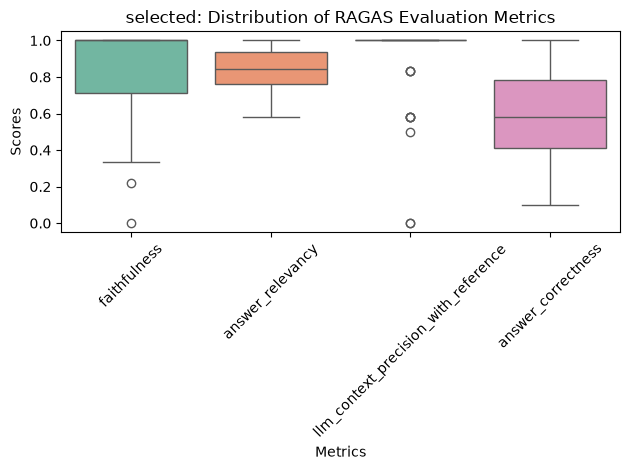

/var/folders/_q/ppmmtcws6nn0nkxcbswtl0vc0000gq/T/ipykernel_12595/70361854.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=means.index, y=means, palette="Set2")


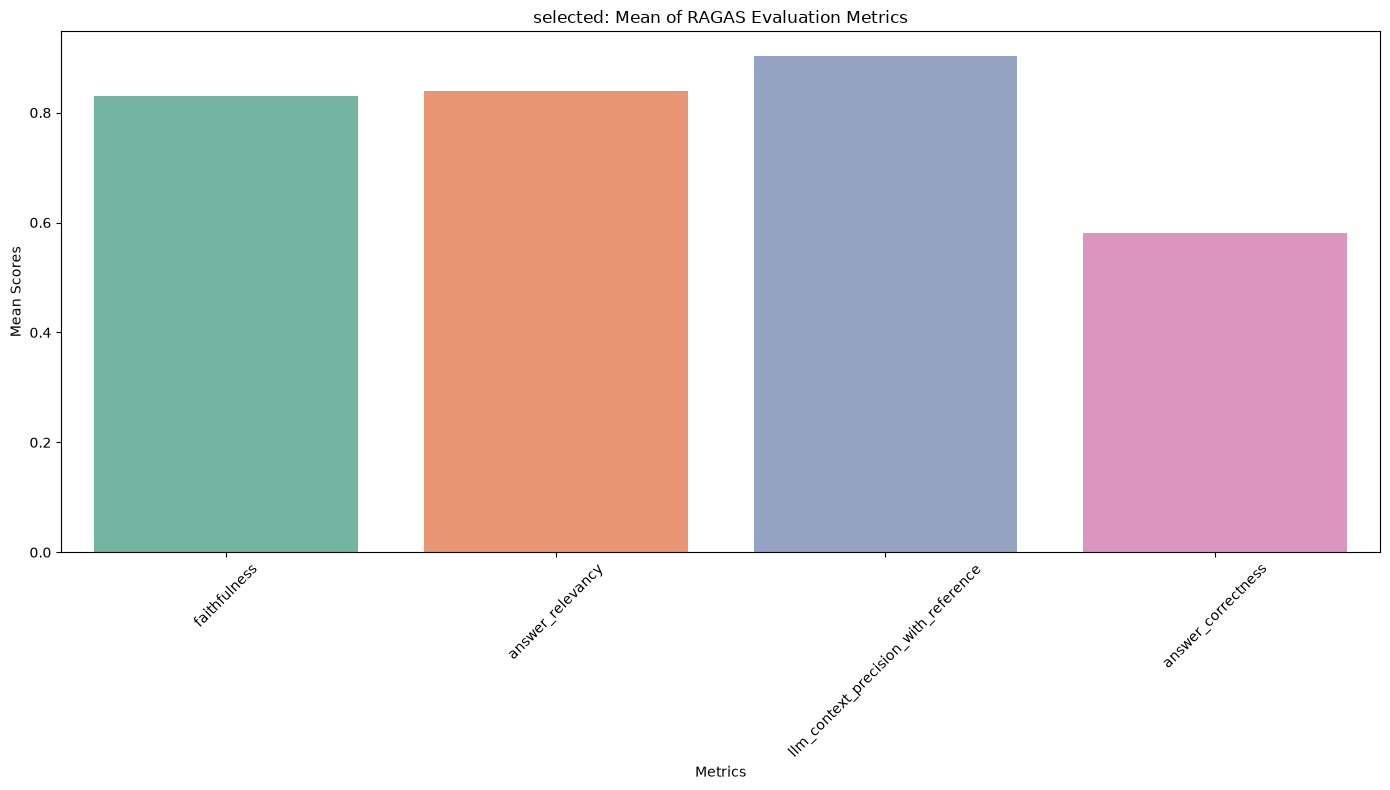

In [121]:
selected_llm_eval_results = get_or_run_llm_eval("selected", selected_dataset, judge)
plot_llm_eval("selected", selected_llm_eval_results)

In [122]:
datasets = {}
for name, chain in chains.items():
    datasets[name] = get_or_create_eval_dataset(name, eval_df, chain)

Loaded qwen3_recursive_256 dataset from data/gold/datasets/qwen3_recursive_256_dataset.json
Loaded qwen3_recursive_1024 dataset from data/gold/datasets/qwen3_recursive_1024_dataset.json
Loaded qwen3_semantic dataset from data/gold/datasets/qwen3_semantic_dataset.json


In [123]:
llm_results = {}
for dataset_name, dataset in datasets.items():
    llm_results[dataset_name] = get_or_run_llm_eval(dataset_name, dataset, judge)

Loaded qwen3_recursive_256 evaluation results from data/gold/results/qwen3_recursive_256_llm_eval_results.csv
Loaded qwen3_recursive_1024 evaluation results from data/gold/results/qwen3_recursive_1024_llm_eval_results.csv
Loaded qwen3_semantic evaluation results from data/gold/results/qwen3_semantic_llm_eval_results.csv


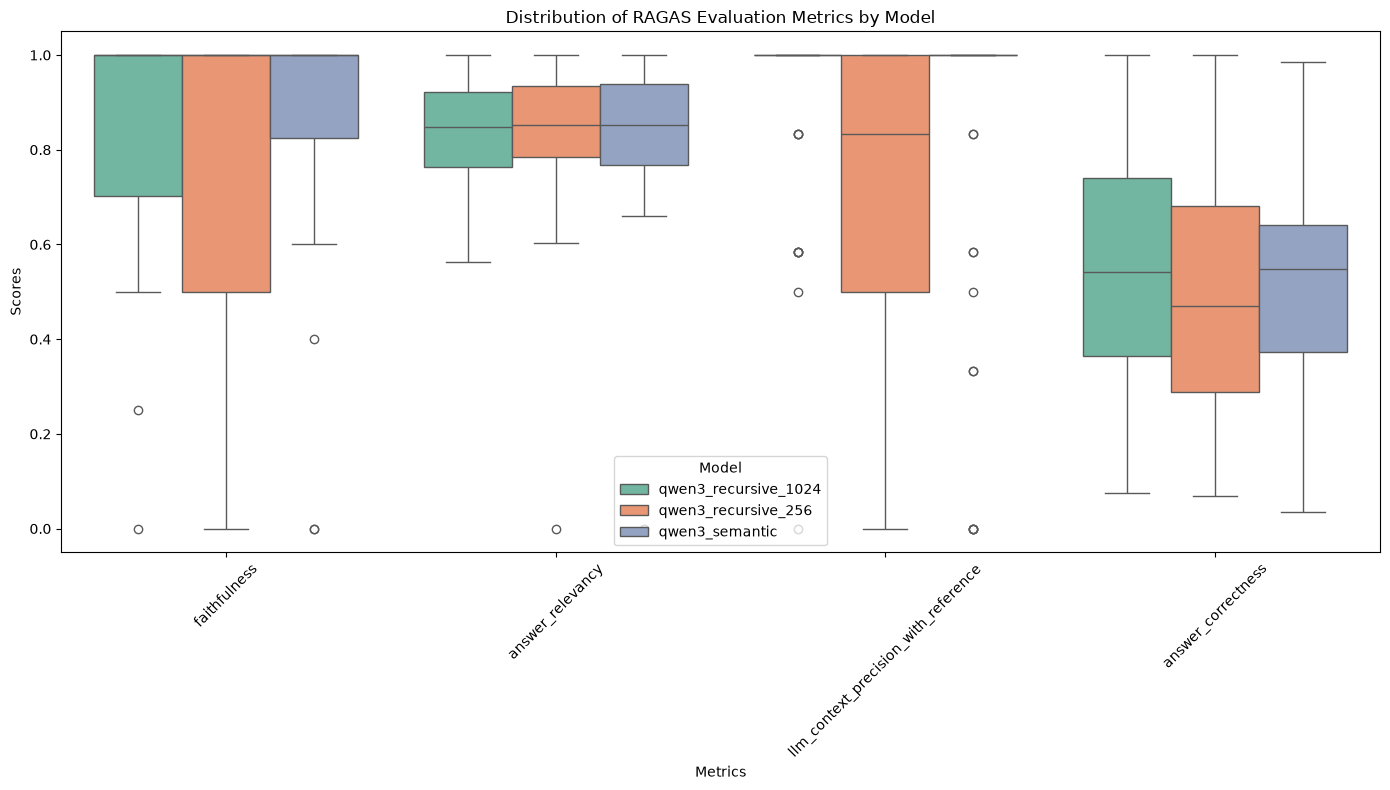

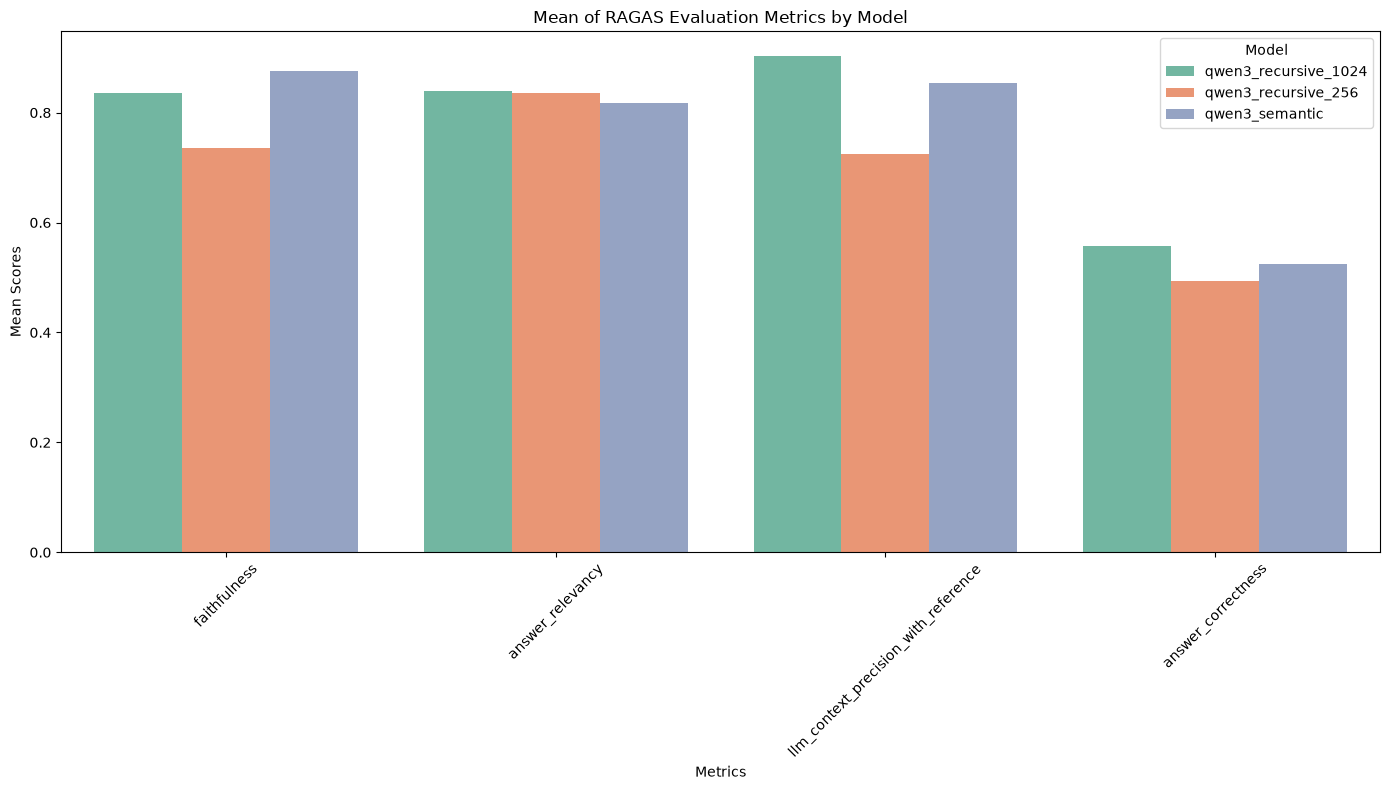

In [124]:
plot_multiple_evals(llm_results)

In [125]:
mean_scores = {}
for name, results in llm_results.items():
    mean_scores[name] = results.select_dtypes(include=[np.float64]).mean()

total_mean_scores = pd.DataFrame(mean_scores).mean()
total_mean_scores.sort_values(ascending=False)

qwen3_recursive_1024    0.783809
qwen3_semantic          0.767714
qwen3_recursive_256     0.697482
dtype: float64

**Results of the reference run** (Qwen3-Embedding-4B, answers by GPT-6.1 Sol, judged by GPT-6 Luna). These results ship in `data.zip`, so you see the same numbers unless you recompute them.

Recursive chunks of 1024 characters perform best (mean over the four metrics 0.78), closely followed by semantic chunks (0.77). The 256-character chunks clearly trail (0.70). Small chunks mainly hurt context precision (0.72 vs. 0.90) and faithfulness (0.74 vs. 0.84): three chunks of about 200 characters often do not contain the complete answer, so the LLM fills the gaps from its own knowledge. Semantic chunks reach the highest faithfulness (0.88) but a lower answer correctness (0.53 vs. 0.56). Their size varies a lot (up to 15,000 characters), and long chunks can mix several topics.

**How large must a difference be to matter?** The `selected` evaluation above uses exactly the same pipeline as `qwen3_recursive_1024`. Still, its answer correctness differs by 0.024 (0.581 vs. 0.557), because neither the generator nor the judge is deterministic. With 48 questions, treat differences below about 0.03 as noise.

In [126]:
best_name = total_mean_scores.idxmax()
best_collection = collections[best_name]
best_store = collection_to_store(best_name, embedding_models[best_name.split("_")[0]])
print(f"Best pipeline: {best_name}")

Best pipeline: qwen3_recursive_1024


## Advanced Methods

In this final section we will look at some more advanced methods to improve our RAG pipeline and comparing them to our best performing pipeline. 

### Multi-Querying

Multi-querying is a technique that involves querying the retrieval model with multiple questions to retrieve relevant chunks. This approach can enhance the retrieval process by leveraging the diversity of queries to capture a broader range of relevant information. By combining the results from multiple queries, we can potentially improve the quality of the retrieved chunks and, consequently, the generated responses. When creating these additional queries the goal is to create queries that are different from the original query but still relevant to the user's information need, i.e variations of the original query.

![multi-querying](https://miro.medium.com/v2/resize:fit:1400/1*wa27F8CbKqYtaRRGyRKy0Q.png)

In [127]:
def generate_query_variations(query: str, num_additional_queries: int) -> List[str]:
    multiquery_prompt = """You are an assistant tasked with generating {num_queries} \
    different versions of the given user question to retrieve relevant documents from a vector \
    database. By generating multiple perspectives on the user question and breaking it down, your goal is to help \
    the user overcome some of the limitations of the distance-based similarity search. \
    Provide these alternative questions separated by newlines without any numbering or listing.
    Original question: {question}
    Alternatives:
    """

    multiquery_chain = ChatPromptTemplate.from_template(multiquery_prompt) | llm
    return multiquery_chain.invoke({"question": query, "num_queries": num_additional_queries}).content.split("\n")

In [128]:
def plot_multiquery_retrieval_results(query: str, collection : Collection, num_additional_queries: int = 3, num_results: int = 3):
    vectors, umap_transform, vectors_projections = get_umap_projection(collection)

    query_projections = project_embeddings(chroma_embedding_functions[collection.name.split("_")[0]].embed_query([query]), umap_transform)

    query_variations = generate_query_variations(query, num_additional_queries)
    query_variations_projections = project_embeddings(chroma_embedding_functions[collection.name.split("_")[0]].embed_query(query_variations), umap_transform)

    original_relevant_docs = collection.query(
        query_texts=[query],
        n_results=num_results,
    )
    original_relevant_docs_ids = [item for sublist in original_relevant_docs["ids"] for item in sublist] # flatten
    original_relevant_docs_embeddings = collection.get(include=["embeddings"], ids=original_relevant_docs_ids)["embeddings"]
    original_relevant_docs_projections = project_embeddings(original_relevant_docs_embeddings, umap_transform)
    
    additional_relevant_docs = collection.query(
        query_texts=query_variations,
        n_results=num_results,
    )
    additional_relevant_docs_ids = [item for sublist in additional_relevant_docs["ids"] for item in sublist] # flatten 
    # remove duplicates
    additional_relevant_docs_ids = list(set(additional_relevant_docs_ids))
    # remove the original relevant docs from the additional relevant docs
    additional_relevant_docs_ids = [doc_id for doc_id in additional_relevant_docs_ids if doc_id not in original_relevant_docs_ids]
    additional_relevant_docs_embeddings = collection.get(include=["embeddings"], ids=additional_relevant_docs_ids)["embeddings"]
    additional_relevant_docs_projections = project_embeddings(additional_relevant_docs_embeddings, umap_transform)

    fig = go.Figure()

    fig.add_trace(go.Scatter(x=vectors_projections[:, 0], y=vectors_projections[:, 1], mode='markers', marker=dict(size=5), name="other vectors"))
    fig.add_trace(go.Scatter(x=query_projections[:, 0], y=query_projections[:, 1], mode='markers', marker=dict(size=7, color='black', symbol='x'), name="original query"))
    fig.add_trace(go.Scatter(x=query_variations_projections[:, 0], y=query_variations_projections[:, 1], mode='markers', marker=dict(size=7, color='red', symbol='x'), name="query variations"))
    fig.add_trace(go.Scatter(x=original_relevant_docs_projections[:, 0], y=original_relevant_docs_projections[:, 1], mode='markers', marker=dict(size=7, color='orange'), name="original relevant docs"))
    fig.add_trace(go.Scatter(x=additional_relevant_docs_projections[:, 0], y=additional_relevant_docs_projections[:, 1], mode='markers', marker=dict(size=7, color='green'), name="additional relevant docs"))
    
    fig.show()

In [129]:
plot_multiquery_retrieval_results("Climate Change", selected_collection)

In [130]:
class MultiQueryRetriever(BaseRetriever):
    store: VectorStore
    num_additional_queries: int = 3
    num_results: int = 3

    def _get_query_variations(self, query: str) -> List[str]:
       return generate_query_variations(query, self.num_additional_queries)

    def _get_relevant_documents(
        self, original_query: str, *, run_manager: CallbackManagerForRetrieverRun
    ) -> List[Document]:
        queries = self._get_query_variations(original_query)
        queries.append(original_query)
        retriever = store_to_retriever(self.store, k=self.num_results)
        relevant_docs = []
        for query in queries:
            results = retriever.invoke(query, config={"callbacks": run_manager.get_child()})
            # remove duplicates
            for res in results:
                if res not in relevant_docs:
                    relevant_docs.append(res)
        return relevant_docs


In [131]:
multiquery_retriever = MultiQueryRetriever(store=best_store, num_additional_queries=3, num_results=3)
multiquery_chain = create_qa_chain(multiquery_retriever)
multiquery_chain.invoke("Where are the biggest increases in wildfire smoke exposure in recent years?")

{'context': [Document(id='6017', metadata={'id': 6017, 'domain': 'cleantechnica', 'title': 'What Does A “ Normal ” Year Of Wildfires Look Like In a Changing Climate?', 'url': 'cleantechnica.com/2023/05/15/what-does-a-normal-year-of-wildfires-look-like-in-a-changing-climate'}, page_content='Surprisingly, some of the biggest increases in wildfire smoke exposure in recent years are in the Great Plains region, from North Dakota to Texas. In addition to their impact on air quality, wildfires can disrupt processes that maintain access to drinking water, including by reducing the ability of soil to absorb water when it rains and sending additional sediment into drinking water systems. The science is clear that climate change is increasing what’ s known as the “ vapor pressure deficit, ” or VPD, across western North America. When VPD is high, the atmosphere can pull more water out of plants, which dries them out and makes them more likely to burn. VPD also is also a good metric for drought, in

In [132]:
datasets["multiquery"] = get_or_create_eval_dataset("multiquery", eval_df, multiquery_chain)

Loaded multiquery dataset from data/gold/datasets/multiquery_dataset.json


In [133]:
llm_results["multiquery"] = get_or_run_llm_eval("multiquery", datasets["multiquery"], judge)

Loaded multiquery evaluation results from data/gold/results/multiquery_llm_eval_results.csv


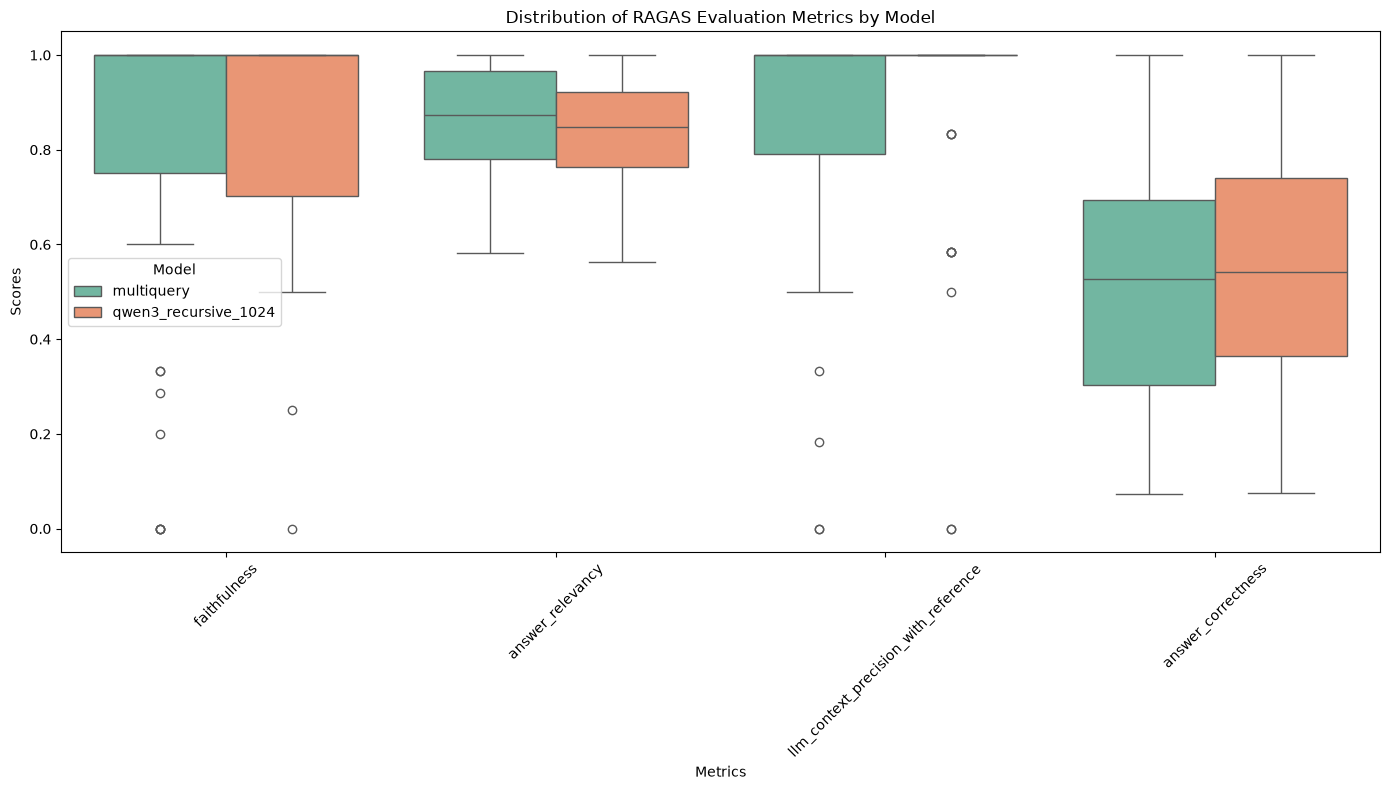

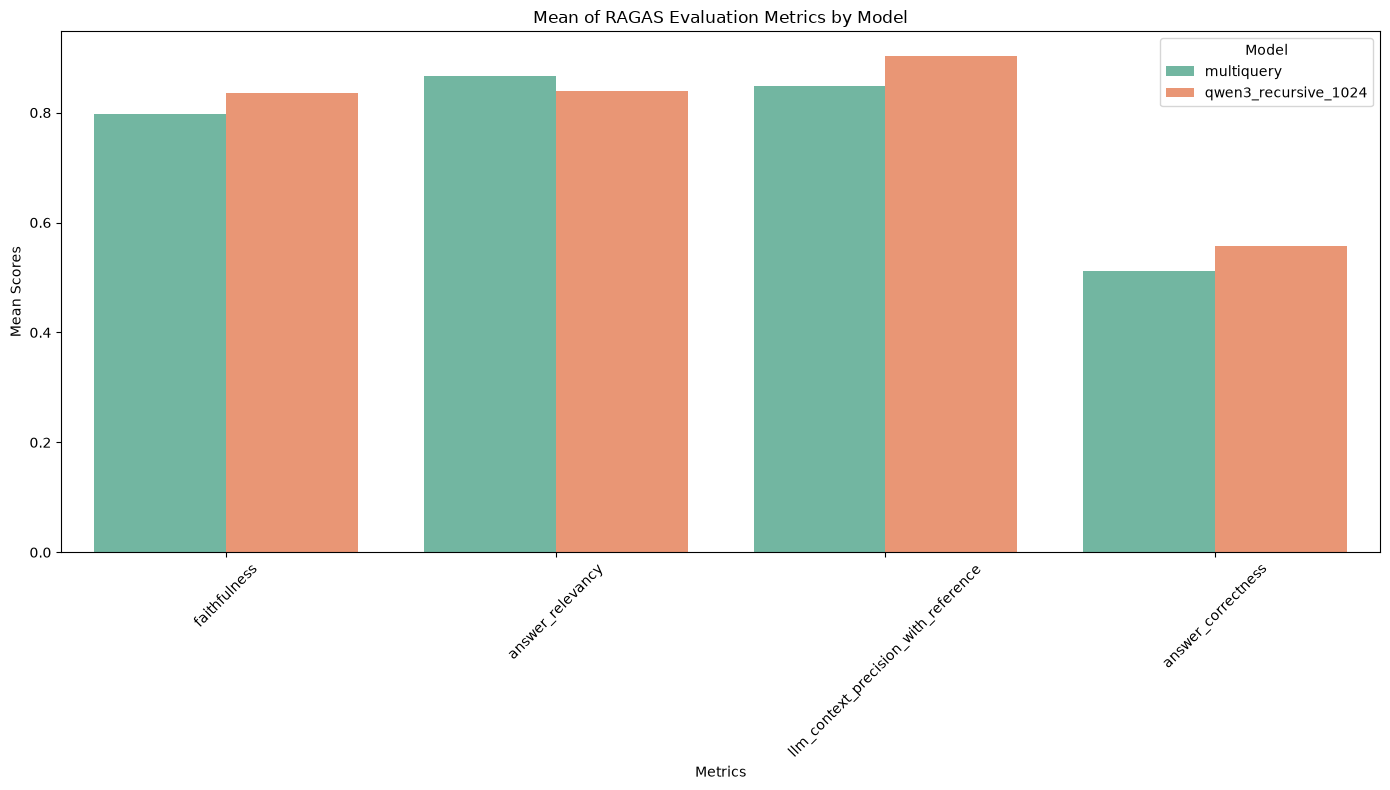

In [134]:
strategy_results = {}
strategy_results[best_name] = llm_results[best_name]
strategy_results["multiquery"] = llm_results["multiquery"]
plot_multiple_evals(strategy_results)

**Results of the reference run:** multi-querying raises answer relevancy (0.87 vs. 0.84), but lowers faithfulness (0.80 vs. 0.84), context precision (0.85 vs. 0.90) and answer correctness (0.51 vs. 0.56). Instead of 3 chunks, the LLM now receives up to 12, and the extra chunks are often only loosely related: the answers become broader and address the question more fully, but they include more statements that are not backed by the reference answer. Most of our questions are specific factual questions answered by a single article. With a strong embedding model, the original query already finds that article, so the variations mostly add noise. Multi-querying pays off more for vague or multi-faceted questions.

### HyDE - Hypothetical Document Embeddings

The idea of the HyDE method is to generate hypothetical documents that are similar to the user query and then retrieve the most similar chunks to these hypothetical documents. This can be useful when the user query is not very specific or when the user query is not very similar to the chunks. The HyDE method can be used to generate hypothetical documents that are more similar to the chunks and therefore improve the retrieval process. Another way to think about it is generating a hypothetical answer and therby reaching an area in the embedding space that is more similar to the actual answer which might not be reachable from the user query.

![hyde](https://miro.medium.com/v2/resize:fit:1200/1*vPX3TZXE5NQ0wHjrpI_muw.png)

In [135]:
def generate_hypothetical_document(query: str, num_hypotheses: int) -> List[str]:
    hyde_prompt = """Please write a news passage about the topic.
    Topic: {query}
    Passage:
    """

    hyde_chain = ChatPromptTemplate.from_template(hyde_prompt) | llm
    hypothetical_documents = [hyde_chain.invoke({"query": query}).content for _ in range(num_hypotheses)]
    return hypothetical_documents

In [136]:
def plot_hyde_retrieval_results(query: str, collection : Collection, num_hypo_documents: int = 2, num_results: int = 3):
    vectors, umap_transform, vectors_projections = get_umap_projection(collection)

    query_projections = project_embeddings(chroma_embedding_functions[collection.name.split("_")[0]].embed_query([query]), umap_transform)

    hypothetical_documents = generate_hypothetical_document(query, num_hypo_documents)
    query_variations_projections = project_embeddings(chroma_embedding_functions[collection.name.split("_")[0]].embed_query(hypothetical_documents), umap_transform)

    original_relevant_docs = collection.query(
        query_texts=[query],
        n_results=num_results,
    )
    original_relevant_docs_ids = [item for sublist in original_relevant_docs["ids"] for item in sublist] # flatten
    original_relevant_docs_embeddings = collection.get(include=["embeddings"], ids=original_relevant_docs_ids)["embeddings"]
    original_relevant_docs_projections = project_embeddings(original_relevant_docs_embeddings, umap_transform)
    
    additional_relevant_docs = collection.query(
        query_texts=hypothetical_documents,
        n_results=num_results,
    )
    additional_relevant_docs_ids = [item for sublist in additional_relevant_docs["ids"] for item in sublist] # flatten 
    # remove duplicates
    additional_relevant_docs_ids = list(set(additional_relevant_docs_ids))
    # remove the original relevant docs from the additional relevant docs
    additional_relevant_docs_ids = [doc_id for doc_id in additional_relevant_docs_ids if doc_id not in original_relevant_docs_ids]
    additional_relevant_docs_embeddings = collection.get(include=["embeddings"], ids=additional_relevant_docs_ids)["embeddings"]
    additional_relevant_docs_projections = project_embeddings(additional_relevant_docs_embeddings, umap_transform)

    fig = go.Figure()

    fig.add_trace(go.Scatter(x=vectors_projections[:, 0], y=vectors_projections[:, 1], mode='markers', marker=dict(size=5), name="other vectors"))
    fig.add_trace(go.Scatter(x=query_projections[:, 0], y=query_projections[:, 1], mode='markers', marker=dict(size=7, color='black', symbol='x'), name="original query"))
    fig.add_trace(go.Scatter(x=query_variations_projections[:, 0], y=query_variations_projections[:, 1], mode='markers', marker=dict(size=7, color='red', symbol='x'), name="hypothetical documents"))
    fig.add_trace(go.Scatter(x=original_relevant_docs_projections[:, 0], y=original_relevant_docs_projections[:, 1], mode='markers', marker=dict(size=7, color='orange'), name="original relevant docs"))
    fig.add_trace(go.Scatter(x=additional_relevant_docs_projections[:, 0], y=additional_relevant_docs_projections[:, 1], mode='markers', marker=dict(size=7, color='green'), name="additional relevant docs"))
    
    fig.show()

In [137]:
plot_hyde_retrieval_results("Climate Change", selected_collection)

In [138]:
class HyDERetriever(BaseRetriever):
    store: VectorStore
    num_hypo_documents: int = 2
    num_results: int = 3

    def _get_hypothetical_documents(self, query: str) -> List[str]:
        return generate_hypothetical_document(query, self.num_hypo_documents)

    def _get_relevant_documents(
        self, original_query: str, *, run_manager: CallbackManagerForRetrieverRun
    ) -> List[Document]:
        hypothetical_documents = self._get_hypothetical_documents(original_query)
        hypothetical_documents.append(original_query)
        retriever = store_to_retriever(self.store, k=self.num_results)
        relevant_docs = []
        for query in hypothetical_documents:
            results = retriever.invoke(query, config={"callbacks": run_manager.get_child()})
            # remove duplicates
            for res in results:
                if res not in relevant_docs:
                    relevant_docs.append(res)
        return relevant_docs


In [139]:
hyde_retriever = HyDERetriever(store=best_store, num_results=3)
hyde_chain = create_qa_chain(hyde_retriever)
hyde_chain.invoke("Where are the biggest increases in wildfire smoke exposure in recent years?")

{'context': [Document(id='6016', metadata={'title': 'What Does A “ Normal ” Year Of Wildfires Look Like In a Changing Climate?', 'id': 6016, 'url': 'cleantechnica.com/2023/05/15/what-does-a-normal-year-of-wildfires-look-like-in-a-changing-climate', 'domain': 'cleantechnica'}, page_content='Five small towns in Oregon—Detroit, Blue River, Vida, Phoenix, and Talent—were lost to the so-called Labor Day Fires in 2020. And in 2021, the Lytton Creek Fire wiped out the village of Lytton, British Columbia, destroying hundreds of homes. All told, between 2017 and 2021, nearly 120,000 fires burned across western North America, burning nearly 39 million acres of land and claiming more than 60,000 structures. The impacts of wildfires reach well beyond the people, communities, and ecosystems that are directly affected by flames. Wildfires have consequences for public health, water supplies, and economies long after a fire is extinguished. Mounting research is showing exposure to the fine particulate

In [140]:
datasets["hyde"] = get_or_create_eval_dataset("hyde", eval_df, hyde_chain)

Loaded hyde dataset from data/gold/datasets/hyde_dataset.json


In [141]:
llm_results["hyde"] = get_or_run_llm_eval("hyde", datasets["hyde"], judge)

Loaded hyde evaluation results from data/gold/results/hyde_llm_eval_results.csv


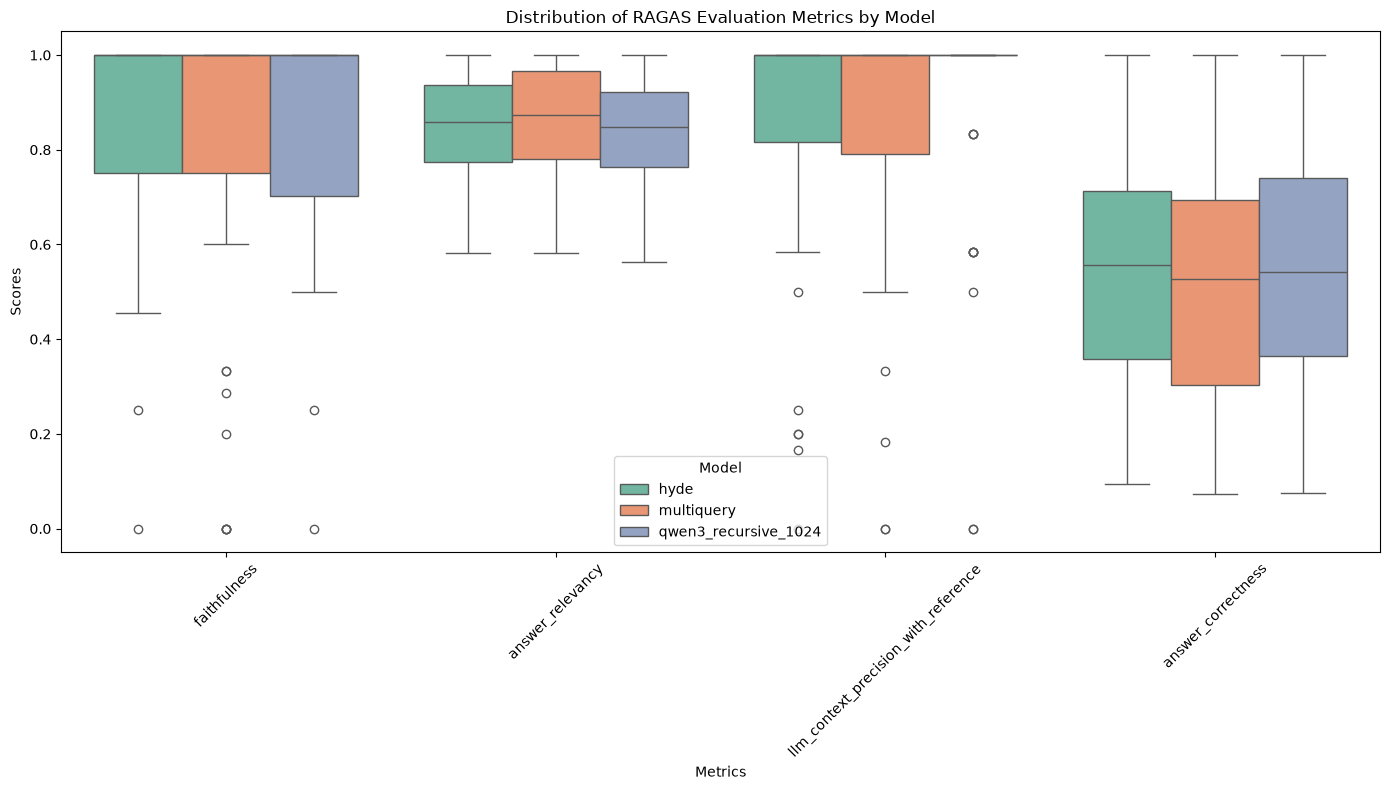

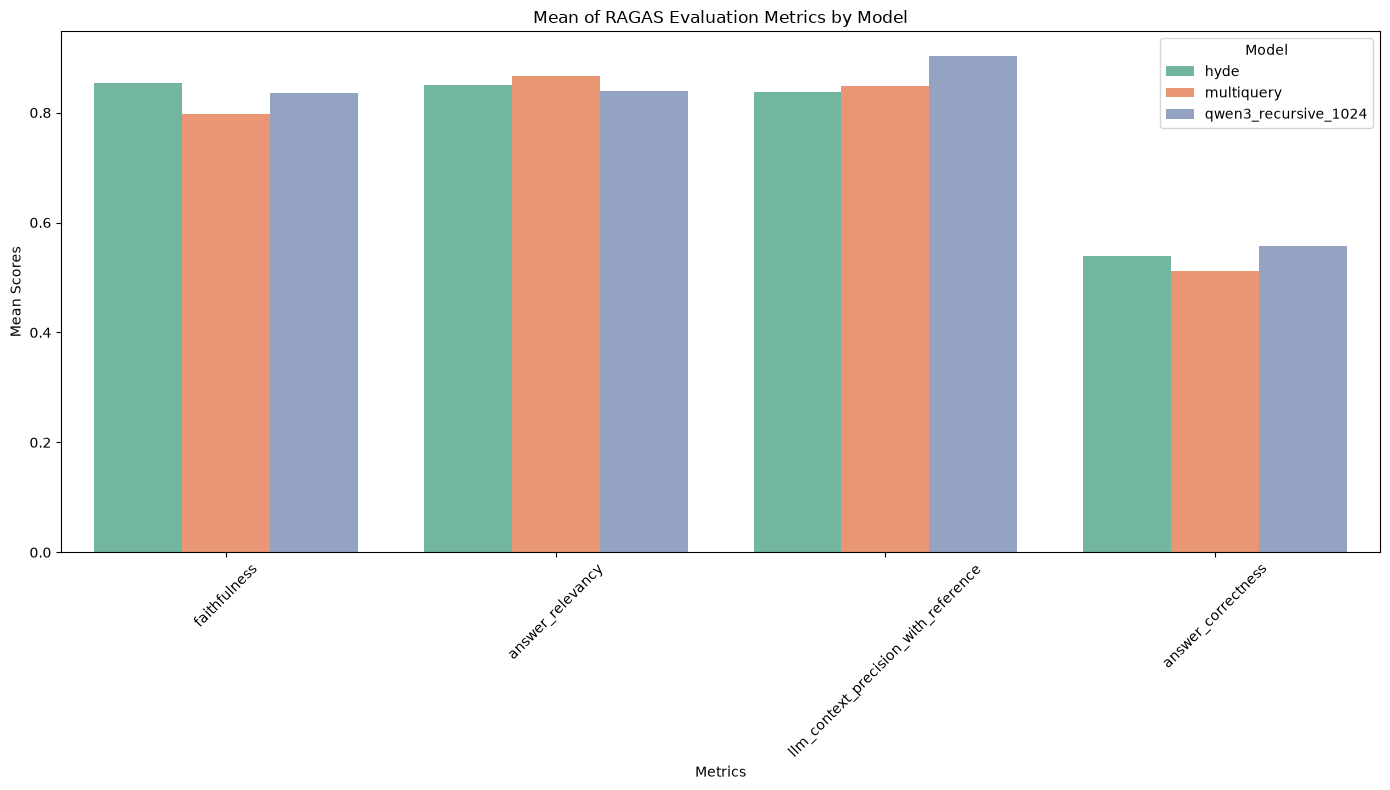

In [142]:
strategy_results["hyde"] = llm_results["hyde"]
plot_multiple_evals(strategy_results)

**Results of the reference run:** HyDE does not improve on the baseline either. Faithfulness and answer relevancy stay within noise (0.85 vs. 0.84), but context precision (0.84 vs. 0.90) and answer correctness (0.54 vs. 0.56) drop. The hypothetical passages are written by the LLM without access to our corpus. For questions about specific news events, they steer the search towards plausible but different articles. HyDE mainly helps when queries and documents look very different, e.g. short keyword queries against long reports. Instruction-tuned query embeddings such as Qwen3's already bridge much of that gap.

### Reranking

Dense retrieval embeds the query and every chunk **independently**: the chunk vectors are computed once, before any question is asked. This is what makes it fast, but the model never sees query and chunk together. A **reranker** (cross-encoder) takes the query and a candidate chunk as one input and judges how well the chunk answers the query. This is far more accurate, but too slow to run over the whole collection. So we combine both: the vector store retrieves a generous candidate set (here 20 chunks), and the reranker re-orders the candidates and keeps the best 3.

We use [Qwen3-Reranker-4B](https://huggingface.co/Qwen/Qwen3-Reranker-4B), the companion of our embedding model. It is a Qwen3 language model that is asked whether a document meets the query's requirements; the relevance score is the probability it assigns to the answer "yes".

![reranking](https://raw.githubusercontent.com/UKPLab/sentence-transformers/master/docs/img/RetrieveRerank.png)

In [143]:
class QwenReranker:
    """Scores (query, document) pairs with Qwen3-Reranker: P("yes") that the document answers the query."""

    def __init__(
            self,
            model_name: str,
            revision: str,
            device: str,
            dtype: torch.dtype,
            instruction: str = "Given a web search query, retrieve relevant passages that answer the query",
            max_length: int = 8192,
            batch_size: int = 4,
    ) -> None:
        self.tokenizer = AutoTokenizer.from_pretrained(model_name, revision=revision, padding_side="left")
        # We pad pre-tokenized ids ourselves (as in the model card); silence the fast-tokenizer hint.
        self.tokenizer.deprecation_warnings["Asking-to-pad-a-fast-tokenizer"] = True
        self.model = AutoModelForCausalLM.from_pretrained(model_name, revision=revision, dtype=dtype).to(device).eval()
        self.device = device
        self.instruction = instruction
        self.max_length = max_length
        self.batch_size = batch_size
        self.yes_id = self.tokenizer.convert_tokens_to_ids("yes")
        self.no_id = self.tokenizer.convert_tokens_to_ids("no")
        # Chat template from the model card: the model answers with a single "yes" or "no".
        prefix = ("<|im_start|>system\nJudge whether the Document meets the requirements based on the Query "
                  "and the Instruct provided. Note that the answer can only be \"yes\" or \"no\".<|im_end|>\n<|im_start|>user\n")
        suffix = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
        self.prefix_ids = self.tokenizer.encode(prefix, add_special_tokens=False)
        self.suffix_ids = self.tokenizer.encode(suffix, add_special_tokens=False)

    @torch.no_grad()
    def score(self, query: str, documents: List[str]) -> List[float]:
        scores = []
        for start in range(0, len(documents), self.batch_size):
            pairs = [f"<Instruct>: {self.instruction}\n<Query>: {query}\n<Document>: {document}"
                     for document in documents[start:start + self.batch_size]]
            encoded = self.tokenizer(
                pairs, padding=False, truncation="longest_first", return_attention_mask=False,
                max_length=self.max_length - len(self.prefix_ids) - len(self.suffix_ids))
            encoded["input_ids"] = [self.prefix_ids + ids + self.suffix_ids for ids in encoded["input_ids"]]
            batch = self.tokenizer.pad(encoded, padding=True, return_tensors="pt").to(self.device)
            # The logits of the last position say how likely the next token is "yes" or "no".
            # logits_to_keep=1 skips the vocabulary projection for all other positions.
            logits = self.model(**batch, logits_to_keep=1).logits[:, -1, :]
            yes_no = torch.stack([logits[:, self.no_id], logits[:, self.yes_id]], dim=1).float()
            scores.extend(torch.softmax(yes_no, dim=1)[:, 1].tolist())
        return scores

In [144]:
RERANKER_MODEL = "Qwen/Qwen3-Reranker-4B"
RERANKER_REVISION = "22e683669bc0f0bd69640a1354a6d0aebcfeede5"

reranker = QwenReranker(RERANKER_MODEL, RERANKER_REVISION, device, dtype)
reranker.score("What do solar panels produce?", [
    "Solar panels convert sunlight into electricity.",
    "Wind turbines are getting taller every year.",
])

Loading checkpoint shards: 100%|██████████| 2/2 [00:11<00:00,  5.60s/it]


[0.977022647857666, 2.0343384676380083e-05]

Let's look at what the reranker does with the candidates for our example question. The table shows the 20 chunks from the vector store in their original order, with the reranker's score and new rank. Chunks that the vector store ranked low can move into the top 3, and vice versa.

In [145]:
def compare_rankings(query: str, store: VectorStore, reranker: QwenReranker, fetch_k: int = 20) -> pd.DataFrame:
    candidates = store.similarity_search(query, k=fetch_k)
    scores = reranker.score(query, [doc.page_content for doc in candidates])
    ranking = pd.DataFrame({
        "dense_rank": range(1, len(candidates) + 1),
        "rerank_score": scores,
        "title": [doc.metadata["title"] for doc in candidates],
        "chunk": [doc.page_content[:120] + "..." for doc in candidates],
    })
    ranking["rerank_rank"] = ranking["rerank_score"].rank(ascending=False, method="first").astype(int)
    return ranking[["dense_rank", "rerank_rank", "rerank_score", "title", "chunk"]]

compare_rankings("Where are the biggest increases in wildfire smoke exposure in recent years?", best_store, reranker)

,dense_rank,rerank_rank,rerank_score,title,chunk
0,1,1,0.999917,What Does A “ Normal ” Year Of Wildfires Look ...,"Surprisingly, some of the biggest increases in..."
1,2,3,0.779993,What Does A “ Normal ” Year Of Wildfires Look ...,"In fact, the state’ s largest fire on record, ..."
2,3,2,0.823328,What Does A “ Normal ” Year Of Wildfires Look ...,"From 2000 to 2021, the average was more than 3..."
3,4,5,0.644225,What Does A “ Normal ” Year Of Wildfires Look ...,"Five small towns in Oregon—Detroit, Blue River..."
4,5,4,0.763484,What Does A “ Normal ” Year Of Wildfires Look ...,The average since of wildfires in western Nort...
5,6,6,0.515620,What Does A “ Normal ” Year Of Wildfires Look ...,"In Colorado, for example, the state’ s three l..."
6,7,9,0.096025,What Does A “ Normal ” Year Of Wildfires Look ...,"That said, above-normal activity is expected f..."
7,8,8,0.136608,What Does A “ Normal ” Year Of Wildfires Look ...,What Does A “ Normal ” Year Of Wildfires Look ...
8,9,7,0.161320,What Does A “ Normal ” Year Of Wildfires Look ...,But climate isn’ t the only factor behind the ...
9,10,10,0.047780,What Does A “ Normal ” Year Of Wildfires Look ...,Let’ s dive into western wildfires by the numb...


Now we wrap this two-stage retrieval in a LangChain retriever, so that it plugs into the same RAG chain as before.

In [146]:
class RerankRetriever(BaseRetriever):
    store: VectorStore
    reranker: Any
    fetch_k: int = 20
    num_results: int = 3

    def _get_relevant_documents(
        self, query: str, *, run_manager: CallbackManagerForRetrieverRun
    ) -> List[Document]:
        retriever = store_to_retriever(self.store, k=self.fetch_k)
        candidates = retriever.invoke(query, config={"callbacks": run_manager.get_child()})
        scores = self.reranker.score(query, [doc.page_content for doc in candidates])
        ranked = sorted(zip(scores, candidates), key=lambda pair: pair[0], reverse=True)
        return [doc for _, doc in ranked[:self.num_results]]


In [147]:
rerank_retriever = RerankRetriever(store=best_store, reranker=reranker, fetch_k=20, num_results=3)
rerank_chain = create_qa_chain(rerank_retriever)
rerank_chain.invoke("Where are the biggest increases in wildfire smoke exposure in recent years?")

{'context': [Document(id='6017', metadata={'url': 'cleantechnica.com/2023/05/15/what-does-a-normal-year-of-wildfires-look-like-in-a-changing-climate', 'id': 6017, 'domain': 'cleantechnica', 'title': 'What Does A “ Normal ” Year Of Wildfires Look Like In a Changing Climate?'}, page_content='Surprisingly, some of the biggest increases in wildfire smoke exposure in recent years are in the Great Plains region, from North Dakota to Texas. In addition to their impact on air quality, wildfires can disrupt processes that maintain access to drinking water, including by reducing the ability of soil to absorb water when it rains and sending additional sediment into drinking water systems. The science is clear that climate change is increasing what’ s known as the “ vapor pressure deficit, ” or VPD, across western North America. When VPD is high, the atmosphere can pull more water out of plants, which dries them out and makes them more likely to burn. VPD also is also a good metric for drought, in

In [148]:
datasets["rerank"] = get_or_create_eval_dataset("rerank", eval_df, rerank_chain)

Loaded rerank dataset from data/gold/datasets/rerank_dataset.json


In [149]:
llm_results["rerank"] = get_or_run_llm_eval("rerank", datasets["rerank"], judge)

Loaded rerank evaluation results from data/gold/results/rerank_llm_eval_results.csv


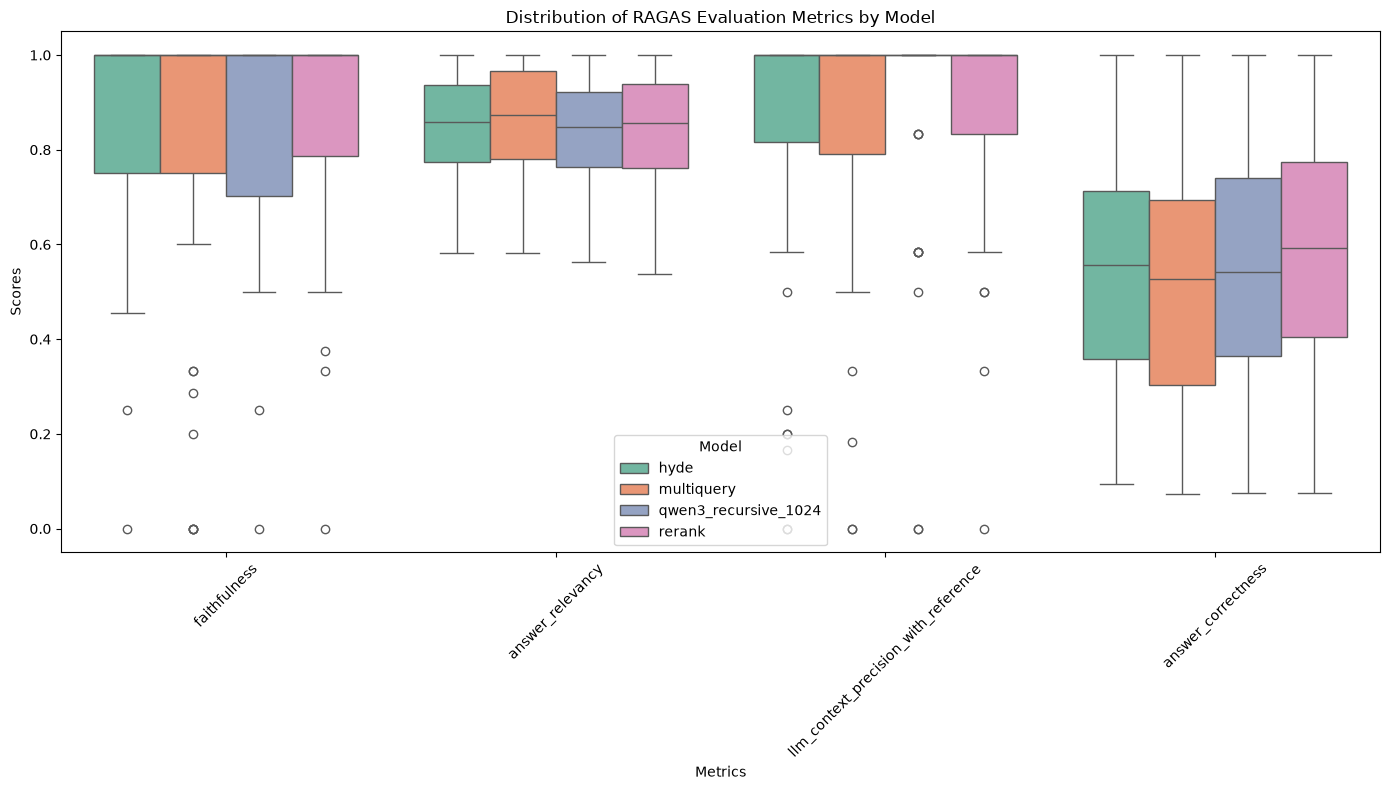

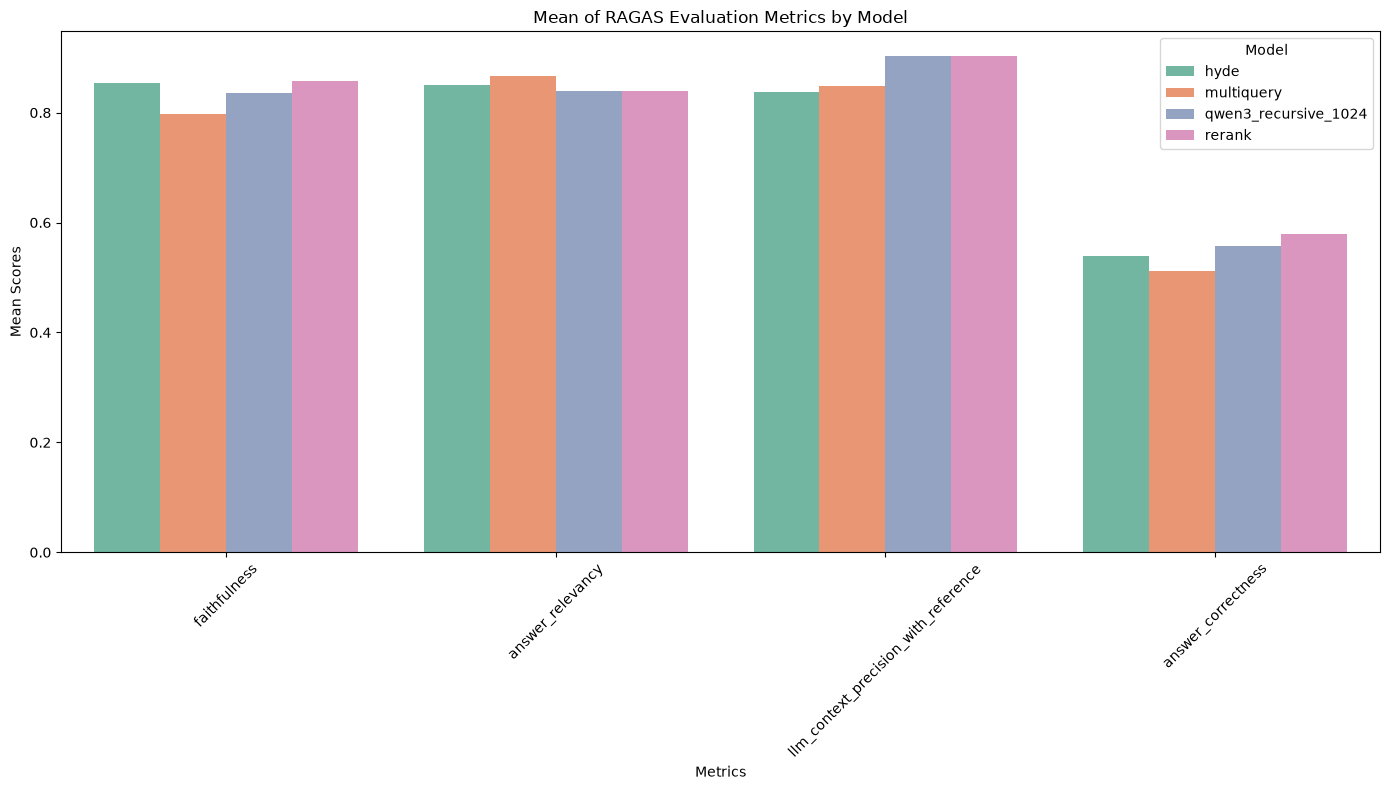

In [150]:
strategy_results["rerank"] = llm_results["rerank"]
plot_multiple_evals(strategy_results)

**Results of the reference run:** the reranker changes the top 3 chunks for 32 of the 48 questions. In the example table it mostly reorders chunks the vector store already ranked highly. In the RAGAS metrics, reranking matches the best baseline: faithfulness 0.86 vs. 0.84, answer correctness 0.58 vs. 0.56–0.58 (the two runs of the baseline), context precision unchanged at 0.90. These differences are within the noise.

Retrieval metrics show the effect more directly. `data/gold/retrieval_metrics.csv` (included in `data.zip`) records whether the article that a human question was written from appears among the top 3 chunks. With reranking, 1024-character chunks find it for 22 instead of 21 of the 23 questions, and the mean reciprocal rank rises from 0.84 to 0.88; semantic chunks go from 18 to 19 hits. Qwen3-Embedding-4B is already a strong retriever, so the reranker has little left to fix on this small question set. Its benefit grows with weaker embedding models, larger collections and more ambiguous questions. It also costs time: on a laptop GPU, scoring 20 candidates takes several seconds per question, compared with milliseconds for the vector search.

### Other Methods

There are many other methods that can be used to improve the RAG pipeline. Some of these include:
- [Step Back](https://arxiv.org/abs/2310.06117): Where the idea is to take a step back and understand the concepts and context of the user query and then use this information to retrieve the most relevant chunks.
- [Hybrid Search](https://medium.com/@zilliz_learn/hybrid-search-combining-text-and-image-for-enhanced-search-capabilities-3d3ce27de326): Where the idea is to not only use semantic search but also lexical search to retrieve the most relevant chunks and combine the results with a re-ranking step.

In [151]:
# Export from a terminal after saving the notebook:
# uv run jupyter nbconvert --to html cleantech_rag.ipynb